In [1]:
# plot / subplot	Plot and subplot identifiers
# date	Measurement date
# vegetation	Vegetation type (TropRF = Tropical Rain Forest)
# map	Mean annual precipitation (mm)
# mat	Mean annual temperature (°C)
# pft_name	Plant functional type (e.g. Evergreen Broadleaf trees)
# latitude / longitude	Plot center coordinates (decimal degrees)
# p_origin	Plot origin type (C = center)
# p_orientation	Plot orientation angle (degrees)
# p_shape	Plot shape (R = rectangle/square)
# p_majoraxis / p_minoraxis	Plot dimensions (m)
# p_geom	Plot boundary as a WKT polygon
# p_epsg	CRS of the geometry (32632 = UTM 32N)
# p_area	Plot area (m²)
# p_mindiam	Minimum diameter threshold for tree inclusion (m)
# sp_ix / sp_iy	Subplot grid index (x and y position)
# dft	Data filtering type (EA = all eligible trees)
# agb	Total aboveground biomass in the subplot (kg)
# agb_valid	Flag: 1 = AGB estimate is valid
# agb_lower / agb_upper	AGB uncertainty bounds (kg)
# agbd_ha	AGB density (Mg/ha, i.e. tonnes per hectare)
# agbd_ha_lower / agbd_ha_upper	AGB density uncertainty bounds (Mg/ha)
# sn / snd_ha	Stem count / stem density (stems per hectare)
# sba / sba_ha	Stem basal area (m²) / basal area density (m²/ha)
# swsg_ba	Basal-area-weighted mean wood specific gravity
# h_t_max	Maximum tree height in the subplot (m)

In [2]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

# 1. Read the CSV
csv_path = "Mondah_Field_Data_Trees.csv"
df = pd.read_csv(csv_path, encoding="latin-1")

# 2. Clean & type-cast coordinates
df["x"] = pd.to_numeric(df["x"], errors="coerce")
df["y"] = pd.to_numeric(df["y"], errors="coerce")
df = df.dropna(subset=["x", "y"])

# 3. Build point geometries (UTM Zone 32N → EPSG:32632)
geometry = [Point(xy) for xy in zip(df["x"], df["y"])]
gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:32632")

# Drop raw x/y columns (now captured in geometry)
gdf = gdf.drop(columns=["x", "y", "epsg"])

# 4. Export to GeoPackage
gdf.to_file("Mondah_Trees.gpkg", driver="GPKG", layer="trees")

print(f"Exported {len(gdf)} trees to Mondah_Trees.gpkg")

Exported 6692 trees to Mondah_Trees.gpkg


In [3]:
import pandas as pd
import geopandas as gpd
from shapely import wkt
from shapely.geometry import box

def plot_csv_to_gpkg(csv_path, output_path, layer_name, side_m):
    df = pd.read_csv(csv_path, encoding="latin-1")
    df["geometry"] = df["p_geom"].apply(wkt.loads)
    gdf = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:32632")
    gdf = gdf.drop(columns=["p_geom", "p_epsg"])

    # Replace with perfect square centered on centroid
    half = side_m / 2
    gdf["geometry"] = gdf.geometry.centroid.apply(
        lambda c: box(c.x - half, c.y - half, c.x + half, c.y + half)
    )

    gdf.to_file(output_path, driver="GPKG", layer=layer_name)
    print(f"Exported {len(gdf)} plots as {side_m}m × {side_m}m squares to {output_path}")

# 0.0625 ha = 25m × 25m
plot_csv_to_gpkg("Mondah_Field_Data_Plot-0_0625ha.csv", "Mondah_Plot_0_0625ha.gpkg", "subplots_25m", 25)
# 0.25 ha = 50m × 50m
plot_csv_to_gpkg("Mondah_Field_Data_Plot-0_25ha.csv",   "Mondah_Plot_0_25ha.gpkg",   "subplots_50m", 50)
# 1 ha = 100m × 100m
plot_csv_to_gpkg("Mondah_Field_Data_Plot-1ha.csv",      "Mondah_Plot_1ha.gpkg",       "subplots_100m", 100)

Exported 240 plots as 25m × 25m squares to Mondah_Plot_0_0625ha.gpkg
Exported 60 plots as 50m × 50m squares to Mondah_Plot_0_25ha.gpkg
Exported 15 plots as 100m × 100m squares to Mondah_Plot_1ha.gpkg


In [4]:
# # Amazon region, Level 1a (default)
# # !python biomass_query.py --level "1a" --bbox -81.0 -20.0 -35.0 10.0 --start 2026-03-01 --end 2026-06-01
# # Level 2a, custom output name
# !python biomass_query.py --level "2a" --bbox -10.0 5.0 15.0 20.0 --output preview.jpg

# # # Pick a specific product from results
# # python biomass_query.py --level "1b" --bbox -81.0 -20.0 -35.0 10.0 --index 3

# # # Custom date range
# # python biomass_query.py --level "1a" --bbox -81.0 -20.0 -35.0 10.0 --start 2026-03-01 --end 2026-06-01

Exists: True
CRS: EPSG:4326
Size: 27103 x 16237
Bands: 7
Resolution: (0.0017980138121629352, 0.0018087108088100656)
NoData: nan
Bounds: BoundingBox(left=4.87621345858588, bottom=-12.429460678142771, right=53.60778180963791, top=16.938576724506266)


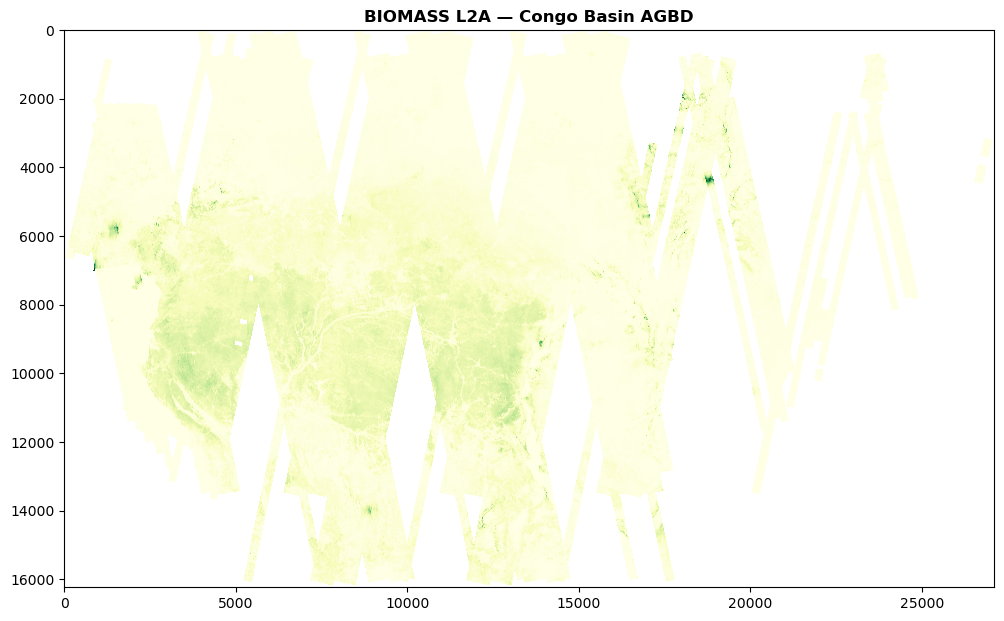

In [5]:
from pathlib import Path
import rasterio
import matplotlib.pyplot as plt
from rasterio.plot import show

tif_path = Path(
    "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/"
    "Biomass_AGBD_Congo_Basin/"
    "agbd_map_L2Afullextent_congo_basin.tif"
)

print("Exists:", tif_path.exists())

with rasterio.open(tif_path) as src:
    print("CRS:", src.crs)
    print("Size:", src.width, "x", src.height)
    print("Bands:", src.count)
    print("Resolution:", src.res)
    print("NoData:", src.nodata)
    print("Bounds:", src.bounds)

    agbd = src.read(1, masked=True)

plt.figure(figsize=(12, 8))
show(agbd, cmap="YlGn", title="BIOMASS L2A — Congo Basin AGBD")
plt.show()

In [6]:
from pathlib import Path

import geopandas as gpd
import rasterio
from rasterio.mask import mask

# Input files
tif_path = Path(
    "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/"
    "Biomass_AGBD_Congo_Basin/"
    "agbd_map_L2Afullextent_congo_basin.tif"
)

gpkg_path = Path(
    "../../../biomass-hackathon-2026/topics/06A-CARBON/"
    "Mondah_Plot_1ha.gpkg"
)

# Save to a writable directory
output_path = Path.cwd() / "Mondah_Plot_1ha_AGBD.tif"

# Read plot boundary
plots = gpd.read_file(gpkg_path)

if plots.empty:
    raise ValueError("The GeoPackage contains no features.")

if plots.crs is None:
    raise ValueError("The plot GeoPackage has no CRS defined.")

with rasterio.open(tif_path) as src:
    # Reproject plot geometry to the raster CRS
    plots_raster_crs = plots.to_crs(src.crs)

    geometries = [
        geom.__geo_interface__
        for geom in plots_raster_crs.geometry
        if geom is not None and not geom.is_empty
    ]

    if not geometries:
        raise ValueError("No valid plot geometries found.")

    # Clip raster to the plot boundary
    nodata_value = src.nodata
    if nodata_value is None:
        nodata_value = -9999.0

    clipped, clipped_transform = mask(
        src,
        geometries,
        crop=True,
        all_touched=False,
        nodata=nodata_value,
        filled=True,
    )

    # Update metadata for the output GeoTIFF
    profile = src.profile.copy()
    profile.update(
        driver="GTiff",
        height=clipped.shape[1],
        width=clipped.shape[2],
        transform=clipped_transform,
        nodata=nodata_value,
        compress="deflate",
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(clipped)

print("Clipping complete!")
print("Output:", output_path)
print("Dimensions:", clipped.shape[2], "×", clipped.shape[1])
print("CRS:", profile["crs"])
print("NoData value:", nodata_value)

Clipping complete!
Output: /home/jovyan/biomass-hackathon-2026/topics/06A-CARBON/Mondah_Plot_1ha_AGBD.tif
Dimensions: 60 × 45
CRS: EPSG:4326
NoData value: nan


In [7]:
"""
Extract AGBD values per plot from a Biomass raster product.
Handles CRS alignment, clipping, and per-plot aggregation.
"""

from pathlib import Path
import numpy as np
import rasterio
from rasterio.mask import mask as rio_mask
import geopandas as gpd

# ── Paths ────────────────────────────────────────────────────────
src_path = Path(
    "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/"
    "Biomass_AGBD_Congo_Basin/"
    "agbd_map_L2Afullextent_congo_basin.tif"
)
gpkg_path = Path("Mondah_Plot_1ha.gpkg")
output_csv = Path("plot_agbd_results.csv")


# ── Helper ───────────────────────────────────────────────────────
def pixel_stats(values, nodata=None):
    """Return dict of stats for a 2-D masked or raw array."""
    a = np.asarray(values, dtype=np.float64).ravel()
    valid = np.isfinite(a)
    if nodata is not None and np.isfinite(nodata):
        valid &= a != nodata
    v = a[valid]
    if v.size == 0:
        return {"n_pixels": 0, "mean": np.nan, "std": np.nan,
                "min": np.nan, "max": np.nan, "median": np.nan}
    return {
        "n_pixels": int(v.size),
        "mean": float(v.mean()),
        "std": float(v.std()),
        "min": float(v.min()),
        "max": float(v.max()),
        "median": float(np.median(v)),
    }


# ── 1. Read the plots ────────────────────────────────────────────
plots = gpd.read_file(gpkg_path)
print(f"Loaded {len(plots)} plots from {gpkg_path}")
print(f"  Plot CRS : {plots.crs}")
print(f"  Plot bounds: {plots.total_bounds}")

# ── 2. Open the raster and reproject plots to match ──────────────
with rasterio.open(src_path) as src:
    print(f"\nRaster CRS : {src.crs}")
    print(f"  Bounds   : {src.bounds}")
    print(f"  Resolution: {src.res}")
    print(f"  NoData   : {src.nodata}")
    print(f"  Dtype    : {src.dtypes[0]}")

    # ── CRS alignment: reproject plots to raster CRS ─────────
    if plots.crs != src.crs:
        print(f"\n  Reprojecting plots from {plots.crs} → {src.crs}")
        plots_aligned = plots.to_crs(src.crs)
    else:
        plots_aligned = plots.copy()

    # ── 3. Quick overlap check ────────────────────────────────
    raster_bounds = src.bounds
    px0, py0, px1, py1 = plots_aligned.total_bounds

    if (px1 < raster_bounds.left or px0 > raster_bounds.right or
            py1 < raster_bounds.bottom or py0 > raster_bounds.top):
        raise ValueError(
            f"No overlap!\n"
            f"  Raster bounds: {raster_bounds}\n"
            f"  Plot bounds  : {plots_aligned.total_bounds}"
        )
    print("  Overlap confirmed ✓")

    # ── 4. Extract per plot ───────────────────────────────────
    results = []

    for idx, row in plots_aligned.iterrows():
        geom = row.geometry
        if geom is None or geom.is_empty:
            print(f"  Plot {idx}: skipped (empty geometry)")
            continue

        # Get the plot name/id if it exists in the columns
        plot_id = row.get("name", row.get("id", row.get("plot_id", idx)))

        try:
            # Clip raster to this plot polygon
            # crop=True shrinks the output to the polygon extent
            # all_touched=True includes pixels partially inside the polygon
            clipped, clipped_transform = rio_mask(
                src,
                [geom.__geo_interface__],
                crop=True,
                all_touched=True,
                nodata=src.nodata,
                filled=True,
            )
        except ValueError as e:
            print(f"  Plot {plot_id}: clip failed – {e}")
            continue

        # clipped shape is (bands, rows, cols); take band 1
        data = clipped[0]
        stats = pixel_stats(data, nodata=src.nodata)

        stats["plot_id"] = plot_id
        stats["area_ha"] = geom.area / 1e4 if src.crs.is_projected else np.nan
        results.append(stats)

        print(
            f"  Plot {plot_id}: "
            f"{stats['n_pixels']} pixels, "
            f"mean AGBD = {stats['mean']:.2f} t/ha"
            if stats['n_pixels'] > 0
            else f"  Plot {plot_id}: no valid pixels"
        )

# ── 5. Save results ──────────────────────────────────────────────
if results:
    import pandas as pd
    df = pd.DataFrame(results)
    # Reorder columns
    cols = ["plot_id", "area_ha", "n_pixels", "mean", "median",
            "std", "min", "max"]
    df = df[[c for c in cols if c in df.columns]]
    df.to_csv(output_csv, index=False)
    print(f"\n✓ Results saved to {output_csv}")
    print(df.to_string(index=False))
else:
    print("\n✗ No results — check that plots overlap the raster.")

Loaded 15 plots from Mondah_Plot_1ha.gpkg
  Plot CRS : EPSG:32632
  Plot bounds: [535135.4709753   59494.04277016 547062.44148922  68242.14145812]

Raster CRS : EPSG:4326
  Bounds   : BoundingBox(left=4.87621345858588, bottom=-12.429460678142771, right=53.60778180963791, top=16.938576724506266)
  Resolution: (0.0017980138121629352, 0.0018087108088100656)
  NoData   : nan
  Dtype    : float32

  Reprojecting plots from EPSG:32632 → EPSG:4326
  Overlap confirmed ✓
  Plot 0: 4 pixels, mean AGBD = 222.31 t/ha
  Plot 1: 2 pixels, mean AGBD = 231.65 t/ha
  Plot 2: 2 pixels, mean AGBD = 179.57 t/ha
  Plot 3: 2 pixels, mean AGBD = 87.82 t/ha
  Plot 4: 4 pixels, mean AGBD = 123.87 t/ha
  Plot 5: 2 pixels, mean AGBD = 136.00 t/ha
  Plot 6: 2 pixels, mean AGBD = 135.58 t/ha
  Plot 7: 4 pixels, mean AGBD = 175.38 t/ha
  Plot 8: 2 pixels, mean AGBD = 80.37 t/ha
  Plot 9: 2 pixels, mean AGBD = 45.94 t/ha
  Plot 10: 4 pixels, mean AGBD = 56.04 t/ha
  Plot 11: 2 pixels, mean AGBD = 51.80 t/ha
  Plot 1

In [8]:
"""
Extract AGBD values per plot from a Biomass raster product.
Handles CRS alignment, fractional-pixel weighting, and per-plot aggregation.
"""

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.features import rasterize
from rasterio.transform import from_bounds
import geopandas as gpd

# ── Paths ────────────────────────────────────────────────────────
src_path = Path(
    "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/"
    "Biomass_AGBD_Congo_Basin/"
    "agbd_map_L2Afullextent_congo_basin.tif"
)
gpkg_path = Path("Mondah_Plot_1ha.gpkg")
output_csv = Path("plot_agbd_results.csv")

OVERSAMPLE = 10  # 10x finer grid for fractional coverage weights


# ── Helper: fractional coverage weights ──────────────────────────
def fractional_weights(geom, data_shape, transform):
    """
    Rasterize the polygon at OVERSAMPLE× resolution, then average
    back to native resolution. Each native pixel gets a weight
    between 0.0 (fully outside) and 1.0 (fully inside).
    """
    h, w = data_shape
    fine_h, fine_w = h * OVERSAMPLE, w * OVERSAMPLE
    bounds = rasterio.transform.array_bounds(h, w, transform)
    fine_transform = from_bounds(*bounds, fine_w, fine_h)

    fine_mask = rasterize(
        [geom.__geo_interface__],
        out_shape=(fine_h, fine_w),
        transform=fine_transform,
        fill=0,
        default_value=1,
        dtype=np.uint8,
    )

    # Average fine cells back to native pixel grid → fraction covered
    weights = fine_mask.reshape(h, OVERSAMPLE, w, OVERSAMPLE).mean(axis=(1, 3))
    return weights


# ── Helper: weighted stats ───────────────────────────────────────
def weighted_stats(data, weights, nodata=None):
    """Compute area-weighted stats over valid pixels."""
    valid = np.isfinite(data) & (weights > 0)
    if nodata is not None and np.isfinite(nodata):
        valid &= data != nodata

    if not valid.any():
        return {
            "n_pixels": 0, "coverage_fraction": 0.0,
            "weighted_mean": np.nan, "simple_mean": np.nan,
            "std": np.nan, "min": np.nan, "max": np.nan, "median": np.nan,
        }

    d = data[valid]
    w = weights[valid]

    wmean = np.average(d, weights=w)
    # Weighted std
    wvar = np.average((d - wmean) ** 2, weights=w)

    return {
        "n_pixels": int(d.size),
        "coverage_fraction": float(w.sum()),
        "weighted_mean": float(wmean),
        "simple_mean": float(d.mean()),
        "std": float(np.sqrt(wvar)),
        "min": float(d.min()),
        "max": float(d.max()),
        "median": float(np.median(d)),
    }


# ── 1. Read the plots ────────────────────────────────────────────
plots = gpd.read_file(gpkg_path)
print(f"Loaded {len(plots)} plots from {gpkg_path}")
print(f"  Plot CRS : {plots.crs}")
print(f"  Plot bounds: {plots.total_bounds}")

# ── 2. Open the raster and reproject plots to match ──────────────
with rasterio.open(src_path) as src:
    print(f"\nRaster CRS : {src.crs}")
    print(f"  Bounds   : {src.bounds}")
    print(f"  Resolution: {src.res}")
    print(f"  NoData   : {src.nodata}")
    print(f"  Dtype    : {src.dtypes[0]}")
    print(f"  Tags     : {src.tags()}")

    # ── CRS alignment ─────────────────────────────────────────
    if plots.crs is None:
        print("  WARNING: plots have no CRS — assuming same as raster")
        plots_aligned = plots.copy()
    elif plots.crs != src.crs:
        print(f"  Reprojecting plots from {plots.crs} → {src.crs}")
        plots_aligned = plots.to_crs(src.crs)
    else:
        plots_aligned = plots.copy()

    # ── 3. Overlap check ──────────────────────────────────────
    rb = src.bounds
    px0, py0, px1, py1 = plots_aligned.total_bounds

    if (px1 < rb.left or px0 > rb.right or
            py1 < rb.bottom or py0 > rb.top):
        raise ValueError(
            f"No overlap!\n"
            f"  Raster bounds: {rb}\n"
            f"  Plot bounds  : {plots_aligned.total_bounds}"
        )
    print("  Overlap confirmed ✓")

    # ── 4. Extract per plot ───────────────────────────────────
    results = []
    id_cols = ["name", "id", "plot_id", "ID", "Name", "PLOT_ID"]

    for idx, row in plots_aligned.iterrows():
        geom = row.geometry
        if geom is None or geom.is_empty:
            print(f"  Plot {idx}: skipped (empty geometry)")
            continue

        # Find a plot identifier from the columns
        plot_id = idx
        for col in id_cols:
            if col in row.index and pd.notna(row[col]):
                plot_id = row[col]
                break

        try:
            clipped, clipped_transform = rio_mask(
                src,
                [geom.__geo_interface__],
                crop=True,
                all_touched=True,
                nodata=src.nodata,
                filled=True,
            )
        except ValueError as e:
            print(f"  Plot {plot_id}: clip failed – {e}")
            continue

        data = clipped[0]

        # Compute fractional coverage weights
        weights = fractional_weights(geom, data.shape, clipped_transform)

        # Compute weighted stats
        stats = weighted_stats(data, weights, nodata=src.nodata)
        stats["plot_id"] = plot_id
        stats["area_ha"] = geom.area / 1e4 if src.crs.is_projected else np.nan
        results.append(stats)

        if stats["n_pixels"] > 0:
            print(
                f"  Plot {plot_id}: "
                f"{stats['n_pixels']} pixels, "
                f"coverage {stats['coverage_fraction']:.1f} px equiv, "
                f"weighted mean = {stats['weighted_mean']:.2f} t/ha, "
                f"simple mean = {stats['simple_mean']:.2f} t/ha"
            )
        else:
            print(f"  Plot {plot_id}: no valid pixels!")

# ── 5. Save results ──────────────────────────────────────────────
if results:
    df = pd.DataFrame(results)
    cols = [
        "plot_id", "area_ha", "n_pixels", "coverage_fraction",
        "weighted_mean", "simple_mean", "median", "std", "min", "max",
    ]
    df = df[[c for c in cols if c in df.columns]]
    df.to_csv(output_csv, index=False)
    print(f"\n✓ Results saved to {output_csv}")
    print(df.to_string(index=False))
else:
    print("\n✗ No results — check that plots overlap the raster.")

Loaded 15 plots from Mondah_Plot_1ha.gpkg
  Plot CRS : EPSG:32632
  Plot bounds: [535135.4709753   59494.04277016 547062.44148922  68242.14145812]

Raster CRS : EPSG:4326
  Bounds   : BoundingBox(left=4.87621345858588, bottom=-12.429460678142771, right=53.60778180963791, top=16.938576724506266)
  Resolution: (0.0017980138121629352, 0.0018087108088100656)
  NoData   : nan
  Dtype    : float32
  Tags     : {'mapping_dx_m': '200.0', 'mapping_dy_m': '200.0', 'min_acquisitions': '1', 'model_backscatter_type': 'delta0', 'model_format': 'biomass_agbd_mapping_model', 'n_acquisitions': '2196', 'predict_max_agbd': '1800.0', 'predict_min_agbd': '0.1', 'AREA_OR_POINT': 'Area'}
  Reprojecting plots from EPSG:32632 → EPSG:4326
  Overlap confirmed ✓
  Plot 0: 4 pixels, coverage 0.2 px equiv, weighted mean = 224.70 t/ha, simple mean = 222.31 t/ha
  Plot 1: 2 pixels, coverage 0.2 px equiv, weighted mean = 231.86 t/ha, simple mean = 231.65 t/ha
  Plot 2: 2 pixels, coverage 0.2 px equiv, weighted mean = 

In [9]:

# If needed, install dependencies in a notebook cell:
# %pip install geopandas rasterio pyarrow fsspec

from pathlib import Path
import geopandas as gpd
import rasterio
from rasterio.merge import merge
from rasterio.mask import mask
from rasterio.windows import from_bounds
import fsspec
import numpy as np

# -----------------------------
# INPUTS
# -----------------------------
gpkg_path = Path("Mondah_Plot_1ha.gpkg")
output_path = Path("Mondah_CHMv2_clipped.tif")

index_url = (
    "https://data.source.coop/tge-labs/meta-chm-v2/tiles.parquet"
)

# -----------------------------
# READ THE PLOT GEOPACKAGE
# -----------------------------
plots = gpd.read_file(gpkg_path)

if plots.crs is None:
    raise ValueError("The GeoPackage has no CRS.")

plots = plots[plots.geometry.notna() & ~plots.geometry.is_empty].copy()

# Tile index spatial query is in geographic coordinates
plots_ll = plots.to_crs("EPSG:4326")
aoi = plots_ll.geometry.union_all()

# -----------------------------
# FIND INTERSECTING CHM TILES
# -----------------------------
with fsspec.open(index_url, "rb") as f:
    tiles = gpd.read_parquet(f)

print("Tile index CRS:", tiles.crs)
print("Tile index columns:", tiles.columns.tolist())

if tiles.crs is None:
    raise ValueError("Tile index has no CRS; inspect its metadata first.")

aoi_for_index = gpd.GeoSeries([aoi], crs="EPSG:4326").to_crs(tiles.crs).iloc[0]

hits = tiles[tiles.geometry.intersects(aoi_for_index)].copy()

if hits.empty:
    raise RuntimeError(
        "No CHM tiles intersect the plots. Check the GeoPackage CRS "
        "and whether CHMv2 covers this location."
    )

print("Intersecting tiles:", len(hits))

# The published tile index documents the source URL as cog_url
if "cog_url" not in hits.columns:
    raise ValueError(
        f"No cog_url column found. Available columns: {hits.columns.tolist()}"
    )

urls = hits["cog_url"].dropna().unique().tolist()
print("Unique raster tiles:", len(urls))

# -----------------------------
# OPEN REMOTE COGS AND MOSAIC AOI
# -----------------------------
plots_metric = plots.to_crs("EPSG:3857")
xmin, ymin, xmax, ymax = plots_metric.total_bounds

srcs = []

try:
    with rasterio.Env(
        AWS_NO_SIGN_REQUEST="YES",
        AWS_REGION="us-east-1",
    ):
        for url in urls:
            print("Opening:", url)
            srcs.append(rasterio.open(url))

        # Read only the AOI bounding window from the COG tiles
        mosaic, mosaic_transform = merge(
            srcs,
            bounds=(xmin, ymin, xmax, ymax),
        )

        profile = srcs[0].profile.copy()
        profile.update(
            driver="GTiff",
            height=mosaic.shape[1],
            width=mosaic.shape[2],
            transform=mosaic_transform,
            count=mosaic.shape[0],
            compress="deflate",
        )

        # Write intermediate mosaic
        temp_mosaic = output_path.with_name("_chm_mosaic_temp.tif")
        with rasterio.open(temp_mosaic, "w", **profile) as dst:
            dst.write(mosaic)

finally:
    for src in srcs:
        src.close()

# -----------------------------
# CLIP TO ALL PLOT POLYGONS
# -----------------------------
with rasterio.open(temp_mosaic) as src:
    plots_src = plots.to_crs(src.crs)
    clipped, clipped_transform = mask(
        src,
        [geom.__geo_interface__ for geom in plots_src.geometry],
        crop=True,
        all_touched=True,
        filled=False,
    )

    out_profile = src.profile.copy()
    out_profile.update(
        driver="GTiff",
        height=clipped.shape[1],
        width=clipped.shape[2],
        transform=clipped_transform,
        compress="deflate",
    )

    with rasterio.open(output_path, "w", **out_profile) as dst:
        dst.write(clipped.filled(0))

temp_mosaic.unlink(missing_ok=True)

print("Saved:", output_path.resolve())


Tile index CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "degree"}]}, "sco

In [10]:
import rasterio

url = "https://data.source.coop/tge-labs/meta-chm-v2/chm/1222233230.tif"

with rasterio.open(url) as src:
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Dimensions:", src.width, "x", src.height)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)

CRS: EPSG:3857
Resolution: (1.1943285669558712, 1.194328566955879)
Dimensions: 32768 x 32768
Bounds: BoundingBox(left=1017529.7205322663, bottom=39135.75848201024, right=1056665.4790142763, top=78271.51696402048)
NoData: None


In [11]:
"""
Update the h_t (height) column in Mondah_Trees.gpkg
using canopy height values from Mondah_CHMv2_clipped.tif.

For each tree point, samples the CHMv2 raster at that location.
"""

from pathlib import Path
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.transform import rowcol

# ── Paths (adjust if needed) ─────────────────────────────────────
base = Path("../../../biomass-hackathon-2026/topics/06A-CARBON")
trees_path = base / "Mondah_Trees.gpkg"
chm_path = base / "Mondah_CHMv2_clipped.tif"
output_path = base / "Mondah_Trees_updated.gpkg"

# ── 1. Load trees ────────────────────────────────────────────────
trees = gpd.read_file(trees_path)
print(f"Loaded {len(trees)} trees")
print(f"  CRS: {trees.crs}")
print(f"  Columns: {trees.columns.tolist()}")
print(f"  h_t before update:")
print(f"    non-null: {trees['h_t'].notna().sum()}")
print(f"    null:     {trees['h_t'].isna().sum()}")
if trees['h_t'].notna().any():
    print(f"    range:    {trees['h_t'].min():.1f} – {trees['h_t'].max():.1f} m")

# ── 2. Open CHM raster and sample at each tree location ──────────
with rasterio.open(chm_path) as src:
    print(f"\nCHM raster:")
    print(f"  CRS: {src.crs}")
    print(f"  Resolution: {src.res}")
    print(f"  Bounds: {src.bounds}")
    print(f"  NoData: {src.nodata}")

    # Reproject trees to match raster CRS if needed
    if trees.crs != src.crs:
        print(f"  Reprojecting trees from {trees.crs} → {src.crs}")
        trees_reproj = trees.to_crs(src.crs)
    else:
        trees_reproj = trees

    # Read the full raster into memory (CHM clip should be small)
    chm_data = src.read(1)
    transform = src.transform
    nodata = src.nodata
    pixel_size = abs(src.res[0])  # meters per pixel

    # Crown search radius in meters — scales with tree size
    # Typical tropical crown radius: 3-8m for big trees
    CROWN_RADIUS_M = 5.0
    radius_px = max(1, int(np.ceil(CROWN_RADIUS_M / pixel_size)))

    print(f"  Pixel size: {pixel_size:.2f} m")
    print(f"  Crown search radius: {CROWN_RADIUS_M} m ({radius_px} pixels)")

    # Sample MAX CHM within crown radius around each tree
    chm_heights = []
    out_of_bounds = 0
    nodata_count = 0

    for idx, row in trees_reproj.iterrows():
        x, y = row.geometry.x, row.geometry.y

        try:
            r, c = rowcol(transform, x, y)

            # Define search window around trunk
            r_min = max(0, r - radius_px)
            r_max = min(chm_data.shape[0], r + radius_px + 1)
            c_min = max(0, c - radius_px)
            c_max = min(chm_data.shape[1], c + radius_px + 1)

            if r_min >= r_max or c_min >= c_max:
                chm_heights.append(np.nan)
                out_of_bounds += 1
                continue

            # Extract window
            window = chm_data[r_min:r_max, c_min:c_max].astype(float)

            # Mask nodata and invalid
            valid_mask = window > 0
            if nodata is not None:
                valid_mask &= window != nodata

            if valid_mask.any():
                # Take the MAX height in the crown area
                chm_heights.append(float(window[valid_mask].max()))
            else:
                chm_heights.append(np.nan)
                nodata_count += 1

        except Exception:
            chm_heights.append(np.nan)
            out_of_bounds += 1

    print(f"\n  Sampled {len(chm_heights)} trees (max within {CROWN_RADIUS_M}m radius):")
    print(f"    Valid heights: {sum(1 for h in chm_heights if not np.isnan(h))}")
    print(f"    Out of bounds: {out_of_bounds}")
    print(f"    NoData pixels: {nodata_count}")

# ── 3. Add h_t_updated column ─────────────────────────────────────
trees["h_t_updated"] = chm_heights

has_chm = trees["h_t_updated"].notna()
print(f"\nBefore capping:")
print(f"  h_t_updated filled:   {has_chm.sum()}")
if has_chm.any():
    print(f"  h_t_updated range: {trees.loc[has_chm, 'h_t_updated'].min():.1f} – {trees.loc[has_chm, 'h_t_updated'].max():.1f} m")
    print(f"  h_t_updated mean:  {trees.loc[has_chm, 'h_t_updated'].mean():.1f} m")

# ── 4. Cap height: understory trees get canopy height, not their own
# If CHM > 1.5× h_t_mod → tree is under canopy → cap at h_t_mod + max growth
# Max growth: ~0.5m/year × 10 years = 5m
CANOPY_THRESHOLD = 1.5
MAX_GROWTH_M = 5.0  # 0.5m/year × 10 years

has_mod = trees["h_t_mod"].notna() & (trees["h_t_mod"] > 0) & (trees["h_t_mod"] != -9999)
has_both = has_chm & has_mod

is_understory = has_both & (trees["h_t_updated"] > trees["h_t_mod"] * CANOPY_THRESHOLD)
is_canopy = has_both & ~is_understory

# Cap understory trees
trees.loc[is_understory, "h_t_updated"] = trees.loc[is_understory, "h_t_mod"] + MAX_GROWTH_M

print(f"\nHeight capping:")
print(f"  Canopy trees (CHM reliable):   {is_canopy.sum()}")
print(f"  Understory trees (capped):     {is_understory.sum()}")
print(f"  No h_t_mod reference:          {(has_chm & ~has_mod).sum()}")

print(f"\nAfter capping:")
if has_chm.any():
    print(f"  h_t_updated range: {trees.loc[has_chm, 'h_t_updated'].min():.1f} – {trees.loc[has_chm, 'h_t_updated'].max():.1f} m")
    print(f"  h_t_updated mean:  {trees.loc[has_chm, 'h_t_updated'].mean():.1f} m")

# ── 4. Save ──────────────────────────────────────────────────────
trees.to_file(output_path, driver="GPKG")
print(f"\n✓ Saved to {output_path}")
print(f"  h_t         = untouched")
print(f"  h_t_mod     = untouched")
print(f"  h_t_updated = new column with CHMv2 values")

Loaded 6692 trees
  CRS: EPSG:32632
  Columns: ['plot', 'subplot', 'tree_date', 'family', 'species', 'wsg', 'tree', 'stem', 'status', 'allom_key', 'a_stem', 'h_t', 'h_t_mod', 'd_stem', 'd_stem_valid', 'd_ht', 'm_agb', 'geometry']
  h_t before update:
    non-null: 6692
    null:     0
    range:    -9999.0 – 59.2 m

CHM raster:
  CRS: EPSG:3857
  Resolution: (1.1943285669558712, 1.194328566955879)
  Bounds: BoundingBox(left=1037026.3478991803, bottom=59918.41532276075, right=1048958.8846116364, top=68728.97716119427)
  NoData: None
  Reprojecting trees from EPSG:32632 → EPSG:3857
  Pixel size: 1.19 m
  Crown search radius: 5.0 m (5 pixels)

  Sampled 6692 trees (max within 5.0m radius):
    Valid heights: 6607
    Out of bounds: 60
    NoData pixels: 25

Before capping:
  h_t_updated filled:   6607
  h_t_updated range: 1.0 – 40.0 m
  h_t_updated mean:  20.2 m

Height capping:
  Canopy trees (CHM reliable):   3247
  Understory trees (capped):     3360
  No h_t_mod reference:          0


In [12]:
# Flag where CHM underestimates
trees["height_diff"] = trees["h_t_updated"] - trees["h_t"]
underestimated = trees["height_diff"] < -5  # CHM more than 5m lower

print(f"CHM underestimates (>5m lower): {underestimated.sum()}")
print(f"CHM matches well (±5m):         {(trees['height_diff'].abs() <= 5).sum()}")
print(f"CHM overestimates (>5m higher): {(trees['height_diff'] > 5).sum()}")

CHM underestimates (>5m lower): 28
CHM matches well (±5m):         68
CHM overestimates (>5m higher): 6511


In [13]:
# Count species
species_counts = trees["species"].value_counts()

print(f"Total unique species: {len(species_counts)}")
print(f"\nSamples per species:")
print(species_counts.to_string())

Total unique species: 174

Samples per species:
species
Aucoumea klaineana             582
Anthocleista sp.               497
Psychotria sp.                 279
Anthostema aubryanum           244
Diospyros sp.                  241
Musanga cecropioides           210
Sorindeia sp.                  208
Dichostemma glaucescens        173
Pycnanthus angolensis          161
Pausinystalia johimbe          152
Cleistopholis sp.              142
Coelocaryon sp.                141
Harungana madagascariensis     123
Xylopia sp.                    122
Macaranga sp.                  104
Alchornea cordifolia           103
Drypetes sp.                   101
Maprounea membranacea           90
Garcinia sp.                    81
Dichaetanthera sp.              79
Scyphocephalium mannii          77
Dacryodes sp.                   75
Dialium bipindense              72
Baphia buettneri                59
Staudtia kamerunensis           58
Xylopia aethiopica              55
Homalium sp.                    50

Total trees loaded: 6692
Trees with valid h_t_mod and d_stem: 6645
Species with >= 30 samples: 37
Trees in those species: 4658

species
Aucoumea klaineana            582
Anthocleista sp.              497
Psychotria sp.                279
Anthostema aubryanum          244
Diospyros sp.                 241
Musanga cecropioides          210
Sorindeia sp.                 208
Dichostemma glaucescens       173
Pycnanthus angolensis         161
Pausinystalia johimbe         152
Cleistopholis sp.             142
Coelocaryon sp.               141
Harungana madagascariensis    123
Xylopia sp.                   122
Macaranga sp.                 104
Alchornea cordifolia          103
Drypetes sp.                  101
Maprounea membranacea          90
Garcinia sp.                   81
Dichaetanthera sp.             78
Scyphocephalium mannii         77
Dacryodes sp.                  75
Dialium bipindense             72
Baphia buettneri               59
Staudtia kamerunensis          58
Xylopia aethio

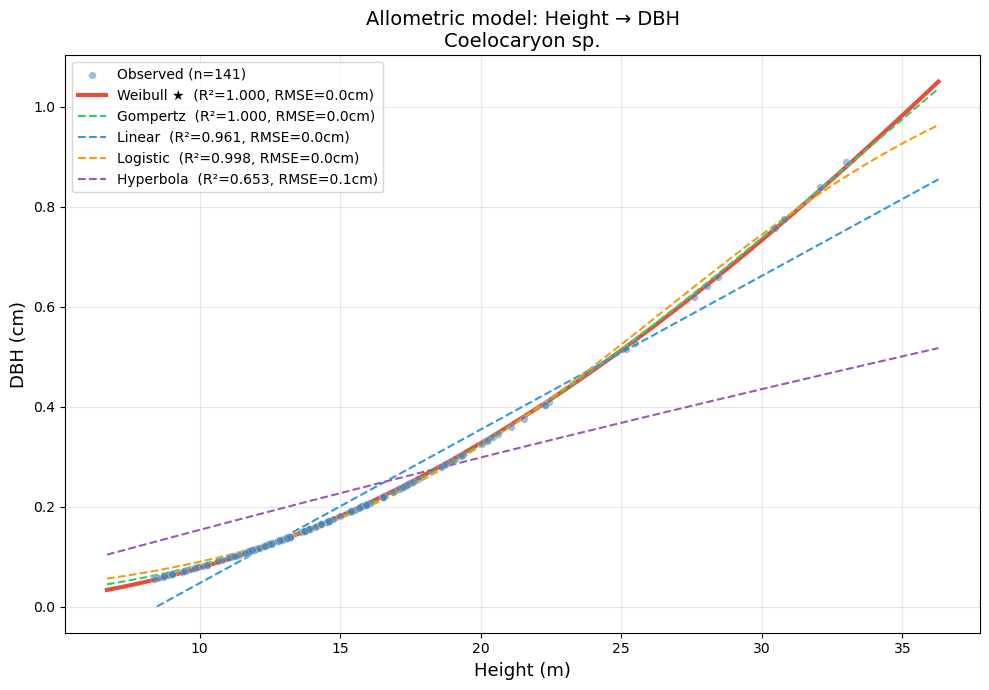


✓ Plot saved to ../../../biomass-hackathon-2026/topics/06A-CARBON/allometric_harungana.png


In [14]:
"""
Allometric model: Height → DBH
- Uses h_t_mod where != -9999
- Only species with >= 30 samples
- Plot for Harungana madagascariensis
"""

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
from pathlib import Path

# ── 1. Load data ─────────────────────────────────────────────────
base = Path("../../../biomass-hackathon-2026/topics/06A-CARBON")
trees = gpd.read_file(base / "Mondah_Trees_updated.gpkg")

print(f"Total trees loaded: {len(trees)}")

# ── 2. Filter: valid h_t_mod and valid d_stem ────────────────────
df = trees[["species", "h_t_mod", "d_stem"]].copy()

# Remove invalid heights
df = df[df["h_t_mod"] != -9999]
df = df[df["h_t_mod"].notna() & (df["h_t_mod"] > 0)]

# Remove invalid diameters
df = df[df["d_stem"].notna() & (df["d_stem"] > 0)]

print(f"Trees with valid h_t_mod and d_stem: {len(df)}")

# ── 3. Species with >= 30 samples ───────────────────────────────
species_counts = df["species"].value_counts()
valid_species = species_counts[species_counts >= 30].index
df_valid = df[df["species"].isin(valid_species)]

print(f"Species with >= 30 samples: {len(valid_species)}")
print(f"Trees in those species: {len(df_valid)}")
print(f"\n{species_counts[species_counts >= 30]}")

# ── 4. Plot Harungana madagascariensis ───────────────────────────
target = "Coelocaryon sp."
df_hm = df[df["species"] == target].copy()

print(f"\n{target}:")
print(f"  Samples: {len(df_hm)}")

if len(df_hm) == 0:
    # Try partial match
    matches = [s for s in df["species"].unique() if "harungana" in s.lower() or "Harungana" in s]
    print(f"  Exact match not found. Possible matches: {matches}")
    if matches:
        target = matches[0]
        df_hm = df[df["species"] == target].copy()
        print(f"  Using: {target} ({len(df_hm)} samples)")

if len(df_hm) < 2:
    raise ValueError(f"Not enough data for {target}")

h = df_hm["h_t_mod"].values
d = df_hm["d_stem"].values

print(f"  Height range: {h.min():.1f} – {h.max():.1f} m")
print(f"  DBH range:    {d.min():.1f} – {d.max():.1f} cm")

# ── 5. Fit allometric models (Height → DBH) ─────────────────────

# Model 1: Weibull — DBH = a * (1 - exp(-b * H^c))
def weibull(h, a, b, c):
    exponent = np.clip(-b * np.power(np.maximum(h, 1e-6), c), -500, 500)
    return a * (1 - np.exp(exponent))

# Model 2: Gompertz — DBH = a * exp(-b * exp(-c * H))
def gompertz(h, a, b, c):
    inner = np.clip(-c * h, -500, 500)
    return a * np.exp(-b * np.exp(inner))

# Model 3: Linear — DBH = a + b * H
def linear(h, a, b):
    return a + b * h

# Model 4: Logistic — DBH = a / (1 + b * exp(-c * H))
def logistic(h, a, b, c):
    exponent = np.clip(-c * h, -500, 500)
    return a / (1 + b * np.exp(exponent))

# Model 5: Hyperbola — DBH = (a * H) / (b + H)
def hyperbola(h, a, b):
    return (a * h) / (b + h)

d_max = max(d)
h_mid = np.median(h)

models = {
    "Weibull": {
        "func": weibull,
        "p0": [d_max * 1.2, 0.05, 1.0],
        "bounds": ([0, 0, 0.01], [d_max * 5, 10, 5]),
    },
    "Gompertz": {
        "func": gompertz,
        "p0": [d_max * 1.2, 3.0, 0.1],
        "bounds": ([0, 0, 0.001], [d_max * 5, 20, 5]),
    },
    "Linear": {
        "func": linear,
        "p0": [0, d_max / max(h)],
        "bounds": ([-np.inf, -np.inf], [np.inf, np.inf]),
    },
    "Logistic": {
        "func": logistic,
        "p0": [d_max * 1.2, 5.0, 0.2],
        "bounds": ([0, 0, 0.001], [d_max * 5, 100, 5]),
    },
    "Hyperbola": {
        "func": hyperbola,
        "p0": [d_max * 2, h_mid],
        "bounds": ([0, 0.01], [d_max * 10, max(h) * 10]),
    },
}

results = {}

for name, m in models.items():
    try:
        popt, _ = curve_fit(m["func"], h, d, p0=m["p0"],
                           bounds=m["bounds"], maxfev=50000)
        d_pred = m["func"](h, *popt)
        ss_res = np.sum((d - d_pred) ** 2)
        ss_tot = np.sum((d - d.mean()) ** 2)
        r2 = 1 - ss_res / ss_tot
        rmse = np.sqrt(np.mean((d - d_pred) ** 2))
        mae = np.mean(np.abs(d - d_pred))
        results[name] = {"params": popt, "func": m["func"],
                         "r2": r2, "rmse": rmse, "mae": mae}
        print(f"\n  {name}: params = {np.round(popt, 4)}")
        print(f"    R² = {r2:.4f}, RMSE = {rmse:.2f} cm, MAE = {mae:.2f} cm")
    except Exception as e:
        print(f"\n  {name}: FAILED — {e}")

# ── 5b. Pick best model ─────────────────────────────────────────
best_name = min(results, key=lambda k: results[k]["rmse"])
best = results[best_name]
print(f"\n  ★ Best model: {best_name} (RMSE = {best['rmse']:.2f} cm, R² = {best['r2']:.4f})")

# ── 6. Plot ──────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 7))

# Scatter points
ax.scatter(h, d, alpha=0.5, s=30, color="steelblue", edgecolors="white",
           linewidth=0.3, label=f"Observed (n={len(df_hm)})", zorder=3)

# Fitted curves — extend range slightly to show curve shape
h_smooth = np.linspace(max(0.5, h.min() * 0.8), h.max() * 1.1, 500)
colors = {"Weibull": "#e74c3c", "Gompertz": "#2ecc71", "Linear": "#3498db",
          "Logistic": "#f39c12", "Hyperbola": "#9b59b6"}

for name, res in results.items():
    with np.errstate(over="ignore", invalid="ignore"):
        d_smooth = res["func"](h_smooth, *res["params"])
    # Remove any NaN/Inf/negative — keeps the line continuous
    valid = np.isfinite(d_smooth) & (d_smooth >= 0)
    lw = 3 if name == best_name else 1.5
    ls = "-" if name == best_name else "--"
    star = " ★" if name == best_name else ""
    ax.plot(h_smooth[valid], d_smooth[valid], color=colors[name],
            linewidth=lw, linestyle=ls,
            label=f'{name}{star}  (R²={res["r2"]:.3f}, RMSE={res["rmse"]:.1f}cm)')

ax.set_xlabel("Height (m)", fontsize=13)
ax.set_ylabel("DBH (cm)", fontsize=13)
ax.set_title(f"Allometric model: Height → DBH\n{target}", fontsize=14)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(base / "allometric_harungana.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\n✓ Plot saved to {base / 'allometric_harungana.png'}")

In [15]:
"""
For each species with >= 30 samples:
  - Fit Weibull, Gompertz, Linear, Logistic, Hyperbola (Height → DBH)
  - Pick best model by lowest RMSE
  - Predict dbh_updated from h_t_updated

For species with < 30 samples:
  - Use a global linear model fitted on ALL valid trees

Adds columns: allom_model, dbh_updated
"""

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from scipy.optimize import curve_fit
import warnings
warnings.filterwarnings("ignore")

# ── Paths ────────────────────────────────────────────────────────
base = Path("../../../biomass-hackathon-2026/topics/06A-CARBON")
trees = gpd.read_file(base / "Mondah_Trees_updated.gpkg")
output_path = base / "Mondah_Trees_updated.gpkg"

print(f"Total trees: {len(trees)}")

# ── Model definitions ────────────────────────────────────────────
def weibull(h, a, b, c):
    exponent = np.clip(-b * np.power(np.maximum(h, 1e-6), c), -500, 500)
    return a * (1 - np.exp(exponent))

def gompertz(h, a, b, c):
    inner = np.clip(-c * h, -500, 500)
    return a * np.exp(-b * np.exp(inner))

def linear(h, a, b):
    return a + b * h

def logistic(h, a, b, c):
    exponent = np.clip(-c * h, -500, 500)
    return a / (1 + b * np.exp(exponent))

def hyperbola(h, a, b):
    return (a * h) / (b + h)


def get_models(d_max, h_mid, h_max):
    return {
        "Weibull": {
            "func": weibull,
            "p0": [d_max * 1.2, 0.05, 1.0],
            "bounds": ([0, 0, 0.01], [d_max * 5, 10, 5]),
        },
        "Gompertz": {
            "func": gompertz,
            "p0": [d_max * 1.2, 3.0, 0.1],
            "bounds": ([0, 0, 0.001], [d_max * 5, 20, 5]),
        },
        "Linear": {
            "func": linear,
            "p0": [0, d_max / max(h_max, 1)],
            "bounds": ([-np.inf, -np.inf], [np.inf, np.inf]),
        },
        "Logistic": {
            "func": logistic,
            "p0": [d_max * 1.2, 5.0, 0.2],
            "bounds": ([0, 0, 0.001], [d_max * 5, 100, 5]),
        },
        "Hyperbola": {
            "func": hyperbola,
            "p0": [d_max * 2, max(h_mid, 1)],
            "bounds": ([0, 0.01], [d_max * 10, h_max * 10]),
        },
    }


def fit_best_model(h, d):
    """Fit all 5 models, return the best one by RMSE."""
    d_max = max(d)
    h_mid = np.median(h)
    h_max = max(h)
    models = get_models(d_max, h_mid, h_max)

    best = None
    for name, m in models.items():
        try:
            popt, _ = curve_fit(m["func"], h, d, p0=m["p0"],
                                bounds=m["bounds"], maxfev=50000)
            d_pred = m["func"](h, *popt)
            ss_res = np.sum((d - d_pred) ** 2)
            ss_tot = np.sum((d - d.mean()) ** 2)
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0
            rmse = np.sqrt(np.mean((d - d_pred) ** 2))

            if best is None or rmse < best["rmse"]:
                best = {
                    "name": name, "func": m["func"],
                    "params": popt, "r2": r2, "rmse": rmse,
                }
        except Exception:
            continue

    return best


# ── 1. Filter valid training data (h_t_mod != -9999 and valid d_stem)
train = trees[["species", "h_t_mod", "d_stem"]].copy()
train = train[
    train["h_t_mod"].notna() & (train["h_t_mod"] > 0) & (train["h_t_mod"] != -9999) &
    train["d_stem"].notna() & (train["d_stem"] > 0)
]
print(f"Valid training pairs (h_t_mod + d_stem): {len(train)}")

# ── 2. Count species ────────────────────────────────────────────
species_counts = train["species"].value_counts()
species_30 = species_counts[species_counts >= 30].index.tolist()
species_under = species_counts[species_counts < 30].index.tolist()

# Also include species not in training data at all
all_species = trees["species"].unique()
species_no_data = [s for s in all_species if s not in species_counts.index]

print(f"\nSpecies with >= 30 samples: {len(species_30)}")
print(f"Species with < 30 samples:  {len(species_under)}")
print(f"Species with no valid data: {len(species_no_data)}")

# ── 3. Fit global fallback (for species with < 30 samples) ──────
# Use hyperbola: DBH = (a * H) / (b + H)
# - Always positive for positive H
# - Passes through origin (H=0 → DBH=0)
# - Saturates at large H (realistic)
h_all = train["h_t_mod"].values
d_all = train["d_stem"].values

d_max_all = max(d_all)
h_mid_all = np.median(h_all)

global_func = hyperbola
global_popt, _ = curve_fit(
    hyperbola, h_all, d_all,
    p0=[d_max_all * 2, h_mid_all],
    bounds=([0, 0.01], [d_max_all * 10, max(h_all) * 10]),
    maxfev=50000,
)
global_pred = hyperbola(h_all, *global_popt)
global_rmse = np.sqrt(np.mean((d_all - global_pred) ** 2))
global_r2_ss = 1 - np.sum((d_all - global_pred)**2) / np.sum((d_all - d_all.mean())**2)

print(f"\nGlobal fallback (Hyperbola): DBH = ({global_popt[0]:.4f} × H) / ({global_popt[1]:.4f} + H)")
print(f"  R² = {global_r2_ss:.4f}, RMSE = {global_rmse:.4f}")

# ── 4. Fit per species ──────────────────────────────────────────
species_models = {}
summary_rows = []

for sp in species_30:
    sp_data = train[train["species"] == sp]
    h = sp_data["h_t_mod"].values
    d = sp_data["d_stem"].values

    best = fit_best_model(h, d)

    if best is not None:
        species_models[sp] = best
        summary_rows.append({
            "species": sp, "n_samples": len(sp_data),
            "model": best["name"], "r2": best["r2"], "rmse": best["rmse"],
        })
        print(f"  {sp:40s} n={len(sp_data):4d}  best={best['name']:10s}  "
              f"R²={best['r2']:.3f}  RMSE={best['rmse']:.1f} cm")
    else:
        print(f"  {sp:40s} n={len(sp_data):4d}  ALL FITS FAILED → global linear")

# ── 5. Print summary table ──────────────────────────────────────
if summary_rows:
    summary_df = pd.DataFrame(summary_rows).sort_values("rmse")
    print(f"\n{'='*80}")
    print("MODEL SELECTION SUMMARY (sorted by RMSE)")
    print(f"{'='*80}")
    print(summary_df.to_string(index=False))
    summary_df.to_csv(base / "allometric_model_summary.csv", index=False)
    print(f"\n✓ Summary saved to {base / 'allometric_model_summary.csv'}")

# ── 6. Store training max height per species (anti-extrapolation) ─
species_h_max = {}
for sp in species_30:
    sp_data = train[train["species"] == sp]
    species_h_max[sp] = sp_data["h_t_mod"].max()

# Global max for fallback species
global_h_max = train["h_t_mod"].max()

print(f"\n{'='*60}")
print("ANTI-EXTRAPOLATION CAPS")
print(f"{'='*60}")
print(f"  Species with caps: {len(species_h_max)}")
print(f"  Global fallback cap: {global_h_max:.1f} m")

# ── 7. Predict dbh_updated using h_t_updated (capped per species)
trees["allom_model"] = ""
trees["dbh_updated"] = np.nan

n_capped = 0

for idx, row in trees.iterrows():
    h_val = row.get("h_t_updated")

    if pd.isna(h_val) or h_val <= 0:
        continue

    sp = row["species"]

    if sp in species_models:
        model = species_models[sp]
        # Cap height at species training max to prevent extrapolation
        h_max = species_h_max[sp]
        if h_val > h_max:
            h_val = h_max
            n_capped += 1
        try:
            with np.errstate(over="ignore", invalid="ignore"):
                dbh_pred = float(model["func"](np.array([h_val]), *model["params"])[0])
            if np.isfinite(dbh_pred) and dbh_pred > 0:
                trees.at[idx, "dbh_updated"] = dbh_pred
                trees.at[idx, "allom_model"] = model["name"]
            else:
                trees.at[idx, "dbh_updated"] = float(hyperbola(min(h_val, global_h_max), *global_popt))
                trees.at[idx, "allom_model"] = "Global_Hyperbola"
        except Exception:
            trees.at[idx, "dbh_updated"] = float(hyperbola(min(h_val, global_h_max), *global_popt))
            trees.at[idx, "allom_model"] = "Global_Hyperbola"
    else:
        # Cap at global max for fallback species
        h_val_capped = min(h_val, global_h_max)
        trees.at[idx, "dbh_updated"] = float(hyperbola(h_val_capped, *global_popt))
        trees.at[idx, "allom_model"] = "Global_Hyperbola"

print(f"  Trees capped at species max: {n_capped}")

# ── 8. Compute agb_updated using Chave 2014 ─────────────────────
# AGB (kg) = 0.0673 × (wsg × D_cm² × H)^0.976
valid_agb = (
    trees["dbh_updated"].notna() & (trees["dbh_updated"] > 0) &
    trees["h_t_updated"].notna() & (trees["h_t_updated"] > 0) &
    trees["wsg"].notna() & (trees["wsg"] > 0)
)

d_cm = trees.loc[valid_agb, "dbh_updated"] * 100  # meters → cm
trees["agb_updated"] = np.nan
trees.loc[valid_agb, "agb_updated"] = 0.0673 * (
    trees.loc[valid_agb, "wsg"] * d_cm**2 * trees.loc[valid_agb, "h_t_updated"]
) ** 0.976

# ── 9. Report ────────────────────────────────────────────────────
has_dbh = trees["dbh_updated"].notna()
has_agb = trees["agb_updated"].notna()

print(f"\n{'='*60}")
print("PREDICTION RESULTS")
print(f"{'='*60}")
print(f"  Total trees:           {len(trees)}")
print(f"  dbh_updated predicted: {has_dbh.sum()}")
print(f"  agb_updated computed:  {has_agb.sum()}")

if has_dbh.any():
    print(f"\n  dbh_updated range: {trees.loc[has_dbh, 'dbh_updated'].min():.4f} – "
          f"{trees.loc[has_dbh, 'dbh_updated'].max():.4f} m")
    print(f"  dbh_updated mean:  {trees.loc[has_dbh, 'dbh_updated'].mean():.4f} m")

if has_agb.any():
    print(f"\n  agb_updated range: {trees.loc[has_agb, 'agb_updated'].min():.1f} – "
          f"{trees.loc[has_agb, 'agb_updated'].max():.1f} kg")
    print(f"  agb_updated mean:  {trees.loc[has_agb, 'agb_updated'].mean():.1f} kg")

# Compare vs original
has_both_agb = has_agb & (trees["m_agb"] > 0)
if has_both_agb.any():
    ratio = trees.loc[has_both_agb, "agb_updated"] / trees.loc[has_both_agb, "m_agb"]
    print(f"\n  agb_updated vs m_agb ({has_both_agb.sum()} trees):")
    print(f"    Mean ratio:   {ratio.mean():.2f}×")
    print(f"    Median ratio: {ratio.median():.2f}×")
    print(f"    >10× original: {(ratio > 10).sum()} trees")

# Model usage
model_counts = trees.loc[has_dbh, "allom_model"].value_counts()
print(f"\n  Model usage:")
for mn, cnt in model_counts.items():
    print(f"    {mn:20s} → {cnt} trees")

# Plot-level AGBD check
print(f"\n{'='*60}")
print("PLOT-LEVEL AGBD (t/ha)")
print(f"{'='*60}")
plots = trees[trees["m_agb"] > 0].groupby("plot").agg(
    m_agb_total=("m_agb", "sum"),
    agb_upd_total=("agb_updated", "sum"),
    n_trees=("m_agb", "count"),
).dropna()
plots["m_agb_tha"] = plots["m_agb_total"] / 1000  # assuming ~1ha plots
plots["agb_upd_tha"] = plots["agb_upd_total"] / 1000
plots["diff_pct"] = ((plots["agb_upd_tha"] - plots["m_agb_tha"]) / plots["m_agb_tha"] * 100)

print(plots[["n_trees", "m_agb_tha", "agb_upd_tha", "diff_pct"]].to_string())

# ── 10. Save ─────────────────────────────────────────────────────
trees.to_file(output_path, driver="GPKG")
print(f"\n✓ Saved to {output_path}")
print(f"  New columns: h_t_corrected, tree_position, allom_model, dbh_updated, agb_updated")

Total trees: 6692
Valid training pairs (h_t_mod + d_stem): 6645

Species with >= 30 samples: 37
Species with < 30 samples:  134
Species with no valid data: 4

Global fallback (Hyperbola): DBH = (6.5987 × H) / (490.6000 + H)
  R² = 0.6350, RMSE = 0.0724
  Aucoumea klaineana                       n= 582  best=Weibull     R²=1.000  RMSE=0.0 cm
  Anthocleista sp.                         n= 497  best=Weibull     R²=1.000  RMSE=0.0 cm
  Psychotria sp.                           n= 279  best=Weibull     R²=1.000  RMSE=0.0 cm
  Anthostema aubryanum                     n= 244  best=Weibull     R²=1.000  RMSE=0.0 cm
  Diospyros sp.                            n= 241  best=Gompertz    R²=1.000  RMSE=0.0 cm
  Musanga cecropioides                     n= 210  best=Weibull     R²=1.000  RMSE=0.0 cm
  Sorindeia sp.                            n= 208  best=Gompertz    R²=1.000  RMSE=0.0 cm
  Dichostemma glaucescens                  n= 173  best=Weibull     R²=1.000  RMSE=0.0 cm
  Pycnanthus angolensis    

In [16]:
# Trees where dbh_updated < d_stem (decreased)
has_both = (trees["d_stem"] > 0) & trees["dbh_updated"].notna()
decreased = trees[has_both & (trees["dbh_updated"] < trees["d_stem"])].copy()

print(f"Trees with decreased DBH: {len(decreased)} / {has_both.sum()}")
print(f"\nSample:")
cols = ["species", "d_stem", "dbh_updated", "h_t_mod", "h_t_updated", "allom_model"]
print(decreased[cols].head(20).to_string())

# How much did they decrease?
diff = decreased["d_stem"] - decreased["dbh_updated"]
print(f"\nDecrease stats:")
print(f"  Mean: {diff.mean()*100:.1f} cm")
print(f"  Max:  {diff.max()*100:.1f} cm")

Trees with decreased DBH: 1619 / 6607

Sample:
                       species  d_stem  dbh_updated  h_t_mod  h_t_updated allom_model
0                Macaranga sp.   0.119     0.064540    12.18          9.0    Gompertz
1                Macaranga sp.   0.102     0.040294    11.28          7.0    Gompertz
2                Macaranga sp.   0.109     0.040294    11.66          7.0    Gompertz
3                Macaranga sp.   0.123     0.040294    12.38          7.0    Gompertz
4                Macaranga sp.   0.109     0.051473    11.66          8.0    Gompertz
5                Macaranga sp.   0.100     0.051473    11.17          8.0    Gompertz
6           Dichaetanthera sp.   0.065     0.064296     9.03          9.0     Weibull
7         Musanga cecropioides   0.090     0.062993    10.60          9.0     Weibull
8                Macaranga sp.   0.085     0.064540    10.31          9.0    Gompertz
9   Harungana madagascariensis   0.082     0.064588    10.13          9.0    Gompertz
10     

In [17]:
import geopandas as gpd
import numpy as np

trees = gpd.read_file("../../../biomass-hackathon-2026/topics/06A-CARBON/Mondah_Trees_updated.gpkg")
plots = gpd.read_file("../../../biomass-hackathon-2026/topics/06A-CARBON/Mondah_Plot_1ha.gpkg")

# Check plot areas
print("Plot geometries:")
print(f"  CRS: {plots.crs}")
if plots.crs.is_projected:
    plots["area_m2"] = plots.geometry.area
else:
    plots_proj = plots.to_crs(plots.estimate_utm_crs())
    plots["area_m2"] = plots_proj.geometry.area

plots["area_ha"] = plots["area_m2"] / 10000
print(plots[["area_ha"]].to_string())

# Now compute AGBD correctly
for idx, plot_row in plots.iterrows():
    plot_name = plot_row.get("name", plot_row.get("plot", idx))
    area_ha = plot_row["area_ha"]
    plot_trees = trees[trees["plot"] == plot_name]
    total_kg = plot_trees.loc[plot_trees["m_agb"] > 0, "m_agb"].sum()
    agbd_tha = total_kg / 1000 / area_ha
    print(f"  {plot_name}: {total_kg:.0f} kg / {area_ha:.2f} ha = {agbd_tha:.1f} t/ha")

Plot geometries:
  CRS: EPSG:32632
    area_ha
0       1.0
1       1.0
2       1.0
3       1.0
4       1.0
5       1.0
6       1.0
7       1.0
8       1.0
9       1.0
10      1.0
11      1.0
12      1.0
13      1.0
14      1.0
  NASA01: 25868 kg / 1.00 ha = 25.9 t/ha
  NASA02: 268659 kg / 1.00 ha = 268.7 t/ha
  NASA03: 48859 kg / 1.00 ha = 48.9 t/ha
  NASA05: 86508 kg / 1.00 ha = 86.5 t/ha
  NASA09: 3440 kg / 1.00 ha = 3.4 t/ha
  NASA10: 99362 kg / 1.00 ha = 99.4 t/ha
  NASA11: 31447 kg / 1.00 ha = 31.4 t/ha
  NASA13: 230972 kg / 1.00 ha = 231.0 t/ha
  NASA14: 147392 kg / 1.00 ha = 147.4 t/ha
  NASA19: 5256 kg / 1.00 ha = 5.3 t/ha
  NASA20: 73427 kg / 1.00 ha = 73.4 t/ha
  NASA21: 3108 kg / 1.00 ha = 3.1 t/ha
  NASA21A: 129911 kg / 1.00 ha = 129.9 t/ha
  NASA22: 268292 kg / 1.00 ha = 268.3 t/ha
  NASA23: 119419 kg / 1.00 ha = 119.4 t/ha


In [18]:
import geopandas as gpd
import numpy as np

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"
trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")

# Only compute where both values are valid and positive
valid = (
    trees["dbh_updated"].notna() & (trees["dbh_updated"] > 0) &
    trees["h_t_updated"].notna() & (trees["h_t_updated"] > 0) &
    trees["wsg"].notna() & (trees["wsg"] > 0)
)

d_cm = trees.loc[valid, "dbh_updated"] * 100  # meters → cm

trees["agb_updated"] = np.nan
trees.loc[valid, "agb_updated"] = 0.0673 * (
    trees.loc[valid, "wsg"] * d_cm**2 * trees.loc[valid, "h_t_updated"]
) ** 0.976

# Stats
computed = trees["agb_updated"].notna()
print(f"agb_updated computed: {computed.sum()} / {len(trees)}")
print(f"  Skipped (negative dbh or missing data): {(~computed).sum()}")
print(f"  Range: {trees.loc[computed, 'agb_updated'].min():.2f} – {trees.loc[computed, 'agb_updated'].max():.2f} kg")
print(f"  Mean:  {trees.loc[computed, 'agb_updated'].mean():.2f} kg")

# Verify against original for first few trees
print("\nSample check:")
print(f"  {'d_stem':>8} {'dbh_upd':>8} {'h_mod':>6} {'h_upd':>6} {'m_agb':>8} {'agb_upd':>8}")
for i in range(50, 89):
    r = trees.iloc[i]
    agb_u = f"{r['agb_updated']:.2f}" if not np.isnan(r.get('agb_updated', np.nan)) else "NaN"
    print(f"  {r['d_stem']:8.4f} {r['dbh_updated']:8.4f} {r['h_t_mod']:6.1f} {r['h_t_updated']:6.1f} {r['m_agb']:8.2f} {agb_u:>8}")

trees.to_file(f"{base}/Mondah_Trees_updated.gpkg", driver="GPKG")
print(f"\n✓ Saved with agb_updated column")

agb_updated computed: 6607 / 6692
  Skipped (negative dbh or missing data): 85
  Range: 0.00 – 10482.79 kg
  Mean:  343.39 kg

Sample check:
    d_stem  dbh_upd  h_mod  h_upd    m_agb  agb_upd
    0.0850   0.0972   10.3   11.0    26.38    36.48
    0.0760      nan    9.8    nan    20.08      NaN
    0.2600   0.0784   17.9   10.0   215.65    11.75
    0.1050   0.1147   11.4   12.0    23.70    29.47
    0.0970   0.1817   11.0   15.0    35.13   161.84
    0.0860   0.1813   10.4   15.0    20.93   128.64
    0.0820   0.1803   10.1   15.0    24.17   165.06
    0.0720   0.1695    9.5   14.5    13.58   109.13
    0.0520   0.1377    8.1   13.1     6.15    65.81
    0.0530   0.1386    8.2   13.2     5.24    54.53
    0.0540   0.1155    8.2   12.0     6.74    42.95
    0.0550   0.1155    8.3   12.0     7.05    42.95
    0.0760   0.0799    9.8   10.0    20.08    22.71
    0.0730   0.0799    9.6   10.0    18.21    22.71
    0.0720   0.0799    9.5   10.0    17.61    22.71
    0.0850   0.0967   10.3 

In [24]:
import geopandas as gpd
import numpy as np
import pandas as pd

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"

# ── 1. Load trees ────────────────────────────────────────────────
trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")

# ── 2. Load plots ────────────────────────────────────────────────
plots = gpd.read_file(f"{base}/Mondah_Plot_1ha.gpkg")

if plots.crs.is_projected:
    plots["area_ha"] = plots.geometry.area / 10000
else:
    plots["area_ha"] = plots.to_crs(plots.estimate_utm_crs()).geometry.area / 10000

# ── 3. Load satellite AGBD (already extracted) ───────────────────
sat = pd.read_csv(f"{base}/plot_agbd_results.csv")
print(f"Satellite data loaded: {len(sat)} plots")
print(sat.head())

# ── 4. Compute field AGBD per plot ───────────────────────────────
results = []

for idx, row in plots.iterrows():
    plot_name = row.get("name", row.get("plot", idx))
    area_ha = row["area_ha"]
    plot_trees = trees[trees["plot"] == plot_name]

    # Field AGBD — updated (2026, from agb_updated)
    total_kg = plot_trees.loc[plot_trees["agb_updated"] > 0, "agb_updated"].sum()
    field_agbd_orig = total_kg / 1000 / area_ha

    # Satellite AGBD — from existing CSV (matched by row index)
    if idx < len(sat):
        sat_agbd = float(sat.iloc[idx]["weighted_mean"]) if pd.notna(sat.iloc[idx]["weighted_mean"]) else np.nan
        n_pixels = int(sat.iloc[idx]["n_pixels"])
    else:
        sat_agbd = np.nan
        n_pixels = 0

    results.append({
        "plot": plot_name,
        "area_ha": round(area_ha, 3),
        "n_trees": len(plot_trees),
        "field_agbd_updated_tha": round(field_agbd_orig, 1),
        "satellite_agbd_tha": round(sat_agbd, 1) if not np.isnan(sat_agbd) else np.nan,
        "n_sat_pixels": n_pixels,
        "diff_sat_vs_field": round(sat_agbd - field_agbd_orig, 1) if not np.isnan(sat_agbd) else np.nan,
        "pct_diff": round((sat_agbd - field_agbd_orig) / field_agbd_orig * 100, 1) if field_agbd_orig > 0 and not np.isnan(sat_agbd) else np.nan,
    })

df = pd.DataFrame(results)

# ── 4. Summary statistics ────────────────────────────────────────
print(f"\n{'='*90}")
print("PLOT-LEVEL AGBD COMPARISON (t/ha)")
print(f"{'='*90}")
print(df.to_string(index=False))

has_sat = df["satellite_agbd_tha"].notna()
bias, rmse, r2 = np.nan, np.nan, np.nan

if has_sat.any():
    diff = df.loc[has_sat, "diff_sat_vs_field"]
    f_vals = df.loc[has_sat, "field_agbd_updated_tha"].values
    s_vals = df.loc[has_sat, "satellite_agbd_tha"].values
    ss_res = np.sum((s_vals - f_vals)**2)
    ss_tot = np.sum((f_vals - f_vals.mean())**2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    bias = diff.mean()
    rmse = np.sqrt((diff**2).mean())

    print(f"\n  Satellite vs Field:")
    print(f"    Bias:  {bias:.1f} t/ha")
    print(f"    RMSE:  {rmse:.1f} t/ha")
    print(f"    R²:    {r2:.4f}")

# ── 5. Export to Excel ───────────────────────────────────────────
excel_path = f"{base}/plot_field_vs_satellite.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    # Sheet 1: Main comparison table
    df.to_excel(writer, sheet_name="Plot_Comparison", index=False)
    
    # Sheet 2: Summary stats
    summary = pd.DataFrame({
        "Metric": ["N plots", "Bias (t/ha)", "RMSE (t/ha)", "R²",
                    "Mean field 2016 (t/ha)", "Mean satellite (t/ha)"],
        "Value": [
            has_sat.sum(),
            round(bias, 1),
            round(rmse, 1),
            round(r2, 4),
            round(df["field_agbd_updated_tha"].mean(), 1),
            round(df.loc[has_sat, "satellite_agbd_tha"].mean(), 1),
        ]
    })
    summary.to_excel(writer, sheet_name="Summary_Stats", index=False)
    
    # Sheet 3: Per-tree sample (first 100)
    tree_cols = ["plot", "species", "d_stem", "dbh_updated", "h_t_mod",
                 "h_t_updated", "wsg", "m_agb", "agb_updated", "allom_model"]
    tree_sample = trees[[c for c in tree_cols if c in trees.columns]].head(100)
    tree_sample.to_excel(writer, sheet_name="Tree_Sample", index=False)

print(f"\n✓ Excel saved to {excel_path}")
print(f"  Sheets: Plot_Comparison, Summary_Stats, Tree_Sample")

Satellite data loaded: 15 plots
   plot_id  area_ha  n_pixels  coverage_fraction  weighted_mean  simple_mean  \
0        0      NaN         4               0.25     224.704263   222.307510   
1        1      NaN         2               0.25     231.863739   231.651520   
2        2      NaN         2               0.25     190.501419   179.572296   
3        3      NaN         2               0.25      86.556473    87.819008   
4        4      NaN         4               0.25     124.570320   123.872414   

       median        std         min         max  
0  227.388474  14.444574  188.568359  245.884735  
1  231.651520   1.039620  230.590469  232.712585  
2  179.572296  14.572174  161.357071  197.787506  
3   87.819008   6.185134   81.506332   94.131683  
4  120.041885  14.877626  107.074242  148.331665  

PLOT-LEVEL AGBD COMPARISON (t/ha)
   plot  area_ha  n_trees  field_agbd_updated_tha  satellite_agbd_tha  n_sat_pixels  diff_sat_vs_field  pct_diff
 NASA01      1.0      260        

DETAILED PLOT INVESTIGATION

──────────────────────────────────────────────────────────────────────
Plot: NASA01  ⚠️ OUTLIER
──────────────────────────────────────────────────────────────────────
  Area: 1.000 ha
  Field AGBD:     25.9 t/ha
  Satellite AGBD: 224.7 t/ha
  Difference:     198.8 t/ha (769%)

  Trees: 260 total, 253 with valid m_agb
  Species: 38 unique

  DBH distribution:
    Mean: 11.7 cm
    Max:  85.2 cm
    <10cm: 142 trees (56%)
    10-30cm: 102 trees
    >30cm: 9 trees (4%)

  Height (h_t_mod) distribution:
    Mean: 11.5 m
    Max:  32.3 m

  CHM height (h_t_updated) distribution:
    Mean: 11.2 m
    Max:  38.0 m

  Top 5 trees hold 41% of plot biomass:
    Aucoumea klaineana              DBH=85cm  H=32m  AGB=3698kg
    Aucoumea klaineana              DBH=70cm  H=29m  AGB=2587kg
    Symphonia globulifera           DBH=46cm  H=24m  AGB=1784kg
    Aucoumea klaineana              DBH=56cm  H=26m  AGB=1593kg
    Vitex sp.                       DBH=38cm  H=22m  AGB=98

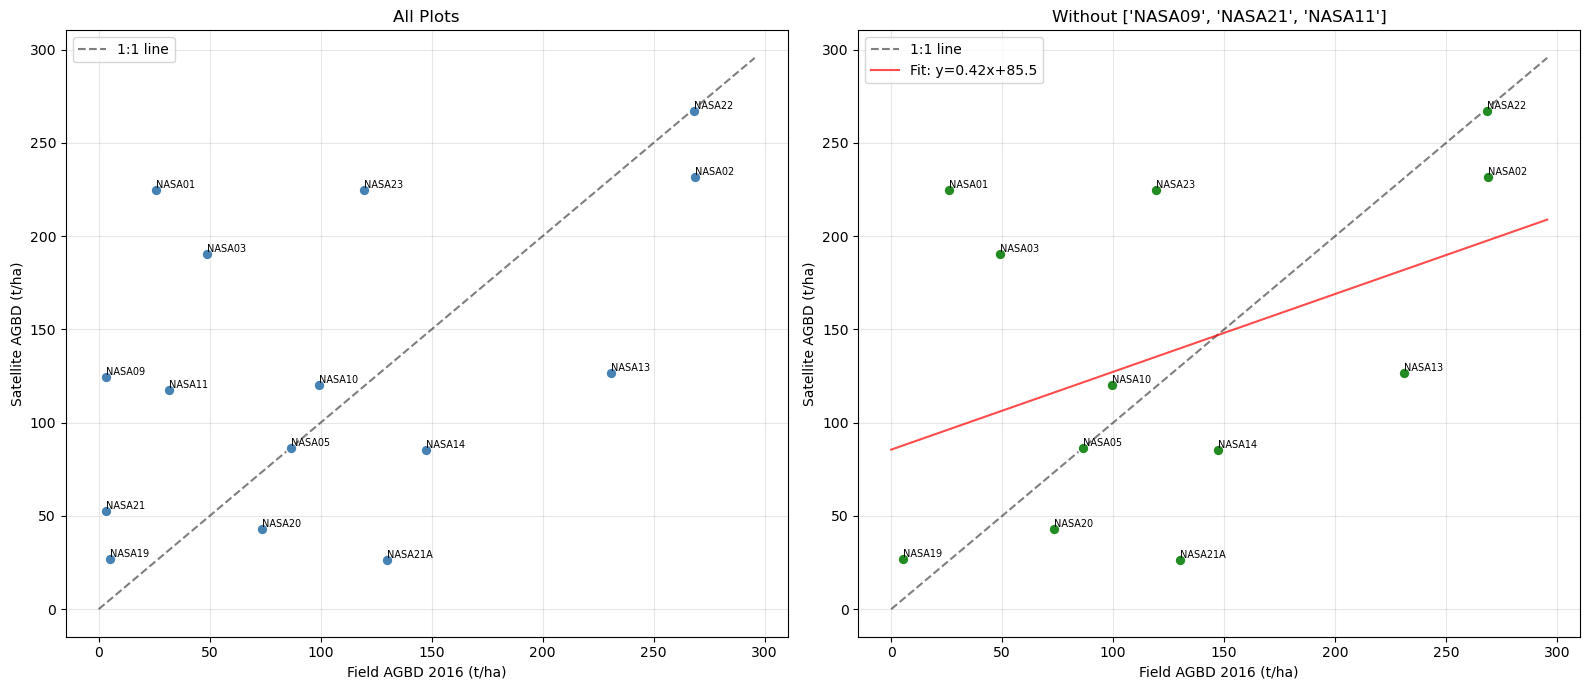


✓ Scatter plot saved


In [25]:
"""
Investigate why some plots have large field vs satellite AGBD mismatch.
"""
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"
trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")
plots = gpd.read_file(f"{base}/Mondah_Plot_1ha.gpkg")
sat = pd.read_csv(f"{base}/plot_agbd_results.csv")

if plots.crs.is_projected:
    plots["area_ha"] = plots.geometry.area / 10000

# ── 1. Per-plot breakdown ────────────────────────────────────────
print("=" * 90)
print("DETAILED PLOT INVESTIGATION")
print("=" * 90)

for idx, row in plots.iterrows():
    pn = row.get("name", row.get("plot", idx))
    ah = row["area_ha"]
    pt = trees[trees["plot"] == pn]

    # Field AGBD
    valid_trees = pt[pt["m_agb"] > 0]
    field_tha = valid_trees["m_agb"].sum() / 1000 / ah

    # Satellite AGBD
    sat_val = float(sat.iloc[idx]["weighted_mean"]) if idx < len(sat) else np.nan
    diff = sat_val - field_tha if not np.isnan(sat_val) else np.nan
    flag = "⚠️ OUTLIER" if abs(diff) > 80 else "✓ OK" if not np.isnan(diff) else ""

    print(f"\n{'─'*70}")
    print(f"Plot: {pn}  {flag}")
    print(f"{'─'*70}")
    print(f"  Area: {ah:.3f} ha")
    print(f"  Field AGBD:     {field_tha:.1f} t/ha")
    print(f"  Satellite AGBD: {sat_val:.1f} t/ha")
    print(f"  Difference:     {diff:.1f} t/ha ({diff/field_tha*100:.0f}%)" if field_tha > 0 and not np.isnan(diff) else "")

    # Tree composition
    print(f"\n  Trees: {len(pt)} total, {len(valid_trees)} with valid m_agb")
    print(f"  Species: {pt['species'].nunique()} unique")

    # Size distribution
    valid_d = pt[(pt["d_stem"] > 0) & (pt["d_stem"] != -9999)]
    if len(valid_d) > 0:
        d_cm = valid_d["d_stem"] * 100
        print(f"\n  DBH distribution:")
        print(f"    Mean: {d_cm.mean():.1f} cm")
        print(f"    Max:  {d_cm.max():.1f} cm")
        print(f"    <10cm: {(d_cm < 10).sum()} trees ({(d_cm < 10).mean()*100:.0f}%)")
        print(f"    10-30cm: {((d_cm >= 10) & (d_cm < 30)).sum()} trees")
        print(f"    >30cm: {(d_cm >= 30).sum()} trees ({(d_cm >= 30).mean()*100:.0f}%)")

    # Height distribution
    valid_h = pt[(pt["h_t_mod"] > 0) & (pt["h_t_mod"] != -9999)]
    if len(valid_h) > 0:
        print(f"\n  Height (h_t_mod) distribution:")
        print(f"    Mean: {valid_h['h_t_mod'].mean():.1f} m")
        print(f"    Max:  {valid_h['h_t_mod'].max():.1f} m")

    # CHM height
    valid_chm = pt[pt["h_t_updated"].notna() & (pt["h_t_updated"] > 0)]
    if len(valid_chm) > 0:
        print(f"\n  CHM height (h_t_updated) distribution:")
        print(f"    Mean: {valid_chm['h_t_updated'].mean():.1f} m")
        print(f"    Max:  {valid_chm['h_t_updated'].max():.1f} m")

    # Top 5 biomass contributors
    top5 = valid_trees.nlargest(5, "m_agb")[["species", "d_stem", "h_t_mod", "m_agb"]]
    if len(top5) > 0:
        top5_pct = top5["m_agb"].sum() / valid_trees["m_agb"].sum() * 100
        print(f"\n  Top 5 trees hold {top5_pct:.0f}% of plot biomass:")
        for _, t in top5.iterrows():
            sp_name = t['species'] if t['species'] else "Unknown"
            print(f"    {sp_name:30s}  DBH={t['d_stem']*100:.0f}cm  H={t['h_t_mod']:.0f}m  AGB={t['m_agb']:.0f}kg")
    # Status of trees (alive/dead?)
    if "status" in pt.columns:
        status_counts = pt["status"].value_counts()
        print(f"\n  Tree status:")
        for s, c in status_counts.items():
            print(f"    {s}: {c}")

# ── 2. Spatial check ─────────────────────────────────────────────
print(f"\n\n{'='*90}")
print("SPATIAL CHECK — Plot centroids & distances")
print(f"{'='*90}")

centroids = plots.geometry.centroid
for i in range(len(plots)):
    pn = plots.iloc[i].get("name", plots.iloc[i].get("plot", i))
    cx, cy = centroids.iloc[i].x, centroids.iloc[i].y
    print(f"  {pn}: centroid=({cx:.0f}, {cy:.0f})")
    # Distance to nearest other plot
    dists = [centroids.iloc[i].distance(centroids.iloc[j]) for j in range(len(plots)) if j != i]
    print(f"    Nearest plot: {min(dists):.0f} m away")

# ── 3. Stats with and without outliers ───────────────────────────
print(f"\n\n{'='*90}")
print("STATS WITH AND WITHOUT OUTLIERS")
print(f"{'='*90}")

# Build comparison df
comp = []
for idx, row in plots.iterrows():
    pn = row.get("name", row.get("plot", idx))
    ah = row["area_ha"]
    pt = trees[trees["plot"] == pn]
    field = pt.loc[pt["m_agb"] > 0, "m_agb"].sum() / 1000 / ah
    sat_val = float(sat.iloc[idx]["weighted_mean"]) if idx < len(sat) and pd.notna(sat.iloc[idx]["weighted_mean"]) else np.nan
    comp.append({"plot": pn, "field": field, "satellite": sat_val})

comp_df = pd.DataFrame(comp).dropna()

def print_stats(label, df):
    diff = df["satellite"] - df["field"]
    f, s = df["field"].values, df["satellite"].values
    ss_res = np.sum((s - f)**2)
    ss_tot = np.sum((f - f.mean())**2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    print(f"\n  {label} (n={len(df)}):")
    print(f"    Bias:  {diff.mean():.1f} t/ha")
    print(f"    RMSE:  {np.sqrt((diff**2).mean()):.1f} t/ha")
    print(f"    R²:    {r2:.4f}")
    print(f"    Mean field:     {f.mean():.1f} t/ha")
    print(f"    Mean satellite: {s.mean():.1f} t/ha")

# All plots
print_stats("ALL PLOTS", comp_df)

# Remove plots where field < 10 t/ha (young regrowth)
mature = comp_df[comp_df["field"] >= 10]
print_stats("MATURE FOREST ONLY (field >= 10 t/ha)", mature)

# Remove plots where abs diff > 100
close = comp_df[abs(comp_df["satellite"] - comp_df["field"]) < 100]
print_stats("CLOSE MATCHES ONLY (|diff| < 100)", close)

# Remove the 3 worst outliers
outliers = ["NASA09", "NASA21", "NASA11"]
no_outliers = comp_df[~comp_df["plot"].isin(outliers)]
print_stats(f"WITHOUT {outliers}", no_outliers)

# ── 4. Scatter plot ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# All plots
ax = axes[0]
ax.scatter(comp_df["field"], comp_df["satellite"], s=60, c="steelblue", edgecolors="white", zorder=3)
for _, r in comp_df.iterrows():
    ax.annotate(r["plot"], (r["field"], r["satellite"]), fontsize=7, ha="left", va="bottom")
lim = max(comp_df["field"].max(), comp_df["satellite"].max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", alpha=0.5, label="1:1 line")
ax.set_xlabel("Field AGBD 2016 (t/ha)")
ax.set_ylabel("Satellite AGBD (t/ha)")
ax.set_title("All Plots")
ax.legend()
ax.grid(alpha=0.3)

# Without outliers
ax = axes[1]
no_out = comp_df[~comp_df["plot"].isin(outliers)]
ax.scatter(no_out["field"], no_out["satellite"], s=60, c="forestgreen", edgecolors="white", zorder=3)
for _, r in no_out.iterrows():
    ax.annotate(r["plot"], (r["field"], r["satellite"]), fontsize=7, ha="left", va="bottom")
lim2 = max(no_out["field"].max(), no_out["satellite"].max()) * 1.1
ax.plot([0, lim2], [0, lim2], "k--", alpha=0.5, label="1:1 line")
# Fit line
from numpy.polynomial.polynomial import polyfit
b, m = polyfit(no_out["field"], no_out["satellite"], 1)
x_fit = np.linspace(0, lim2, 100)
ax.plot(x_fit, b + m * x_fit, "r-", alpha=0.7, label=f"Fit: y={m:.2f}x+{b:.1f}")
ax.set_xlabel("Field AGBD 2016 (t/ha)")
ax.set_ylabel("Satellite AGBD (t/ha)")
ax.set_title(f"Without {outliers}")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{base}/field_vs_satellite_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\n✓ Scatter plot saved")

Raster CRS: EPSG:4326
Raster resolution: 0.0 × 0.0 m
Raster bounds: BoundingBox(left=4.87621345858588, bottom=-12.429460678142771, right=53.60778180963791, top=16.938576724506266)

Plot size: ~100m × 100m (1 ha)
Pixel size: 0m × 0m
→ Each plot covers 55616.9 × 55288.0 pixels
  That means each plot sits inside ~3074952696 pixels

    Plot          Plot_center         Pixel_center  Offset(m)  N_px                      Px_values
  NASA01 (9,1) (9,1)        0.0     4             224, 246, 230, 189
  NASA02 (9,1) (9,1)        0.0     2                       231, 233
  NASA03 (9,1) (9,1)        0.0     2                       161, 198
  NASA05 (9,1) (9,1)        0.0     2                         82, 94
  NASA09 (9,1) (9,1)        0.0     4             124, 148, 107, 116
  NASA10 (9,1) (9,1)        0.0     2                       162, 110
  NASA11 (9,1) (9,1)        0.0     2                       166, 105
  NASA13 (9,1) (9,1)        0.0     4             258, 120, 195, 128
  NASA14 (9,1) (9,

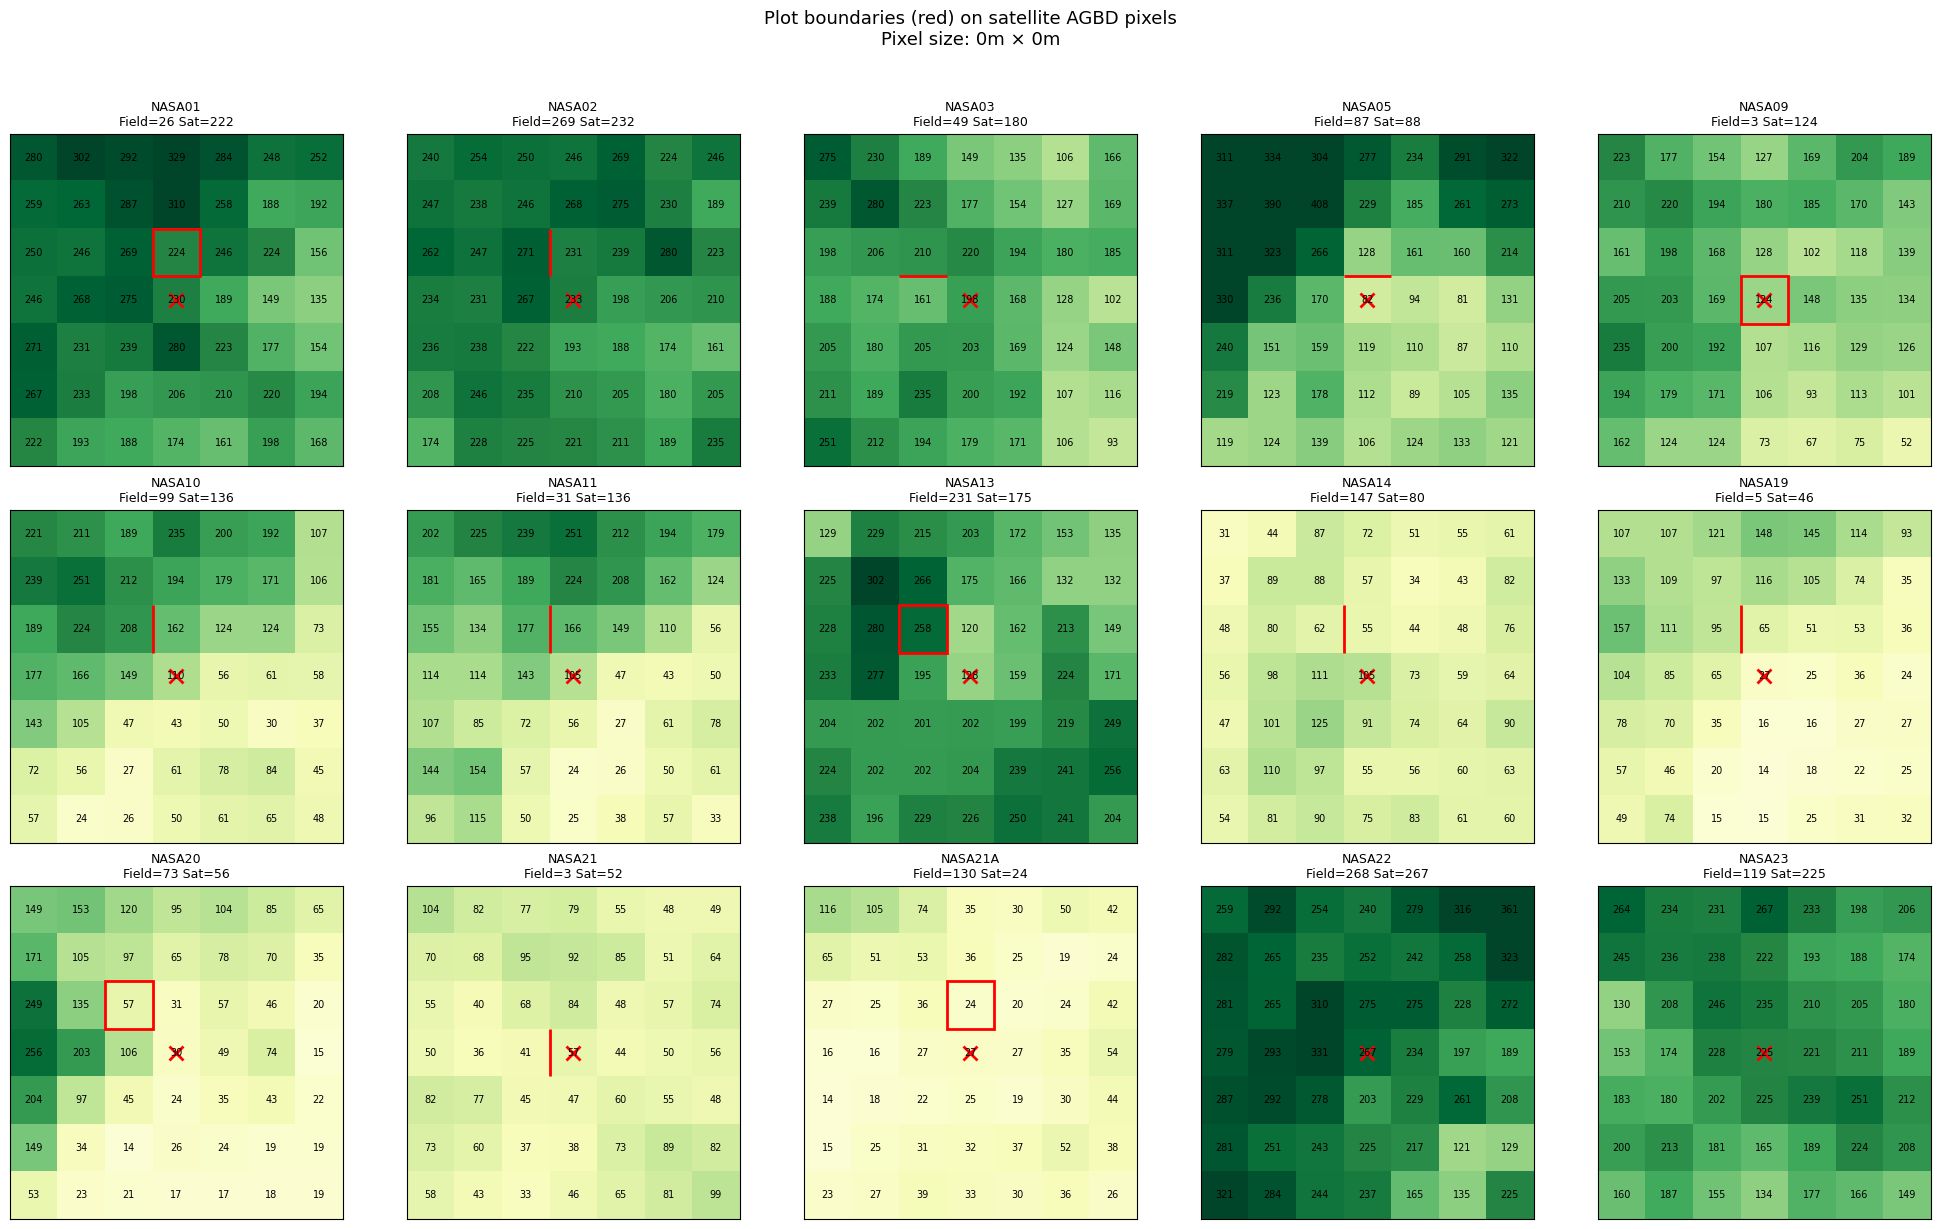


✓ Spatial overlap plot saved


In [26]:
"""
Check spatial overlap between field plots and satellite raster pixels.
Shows how many pixels each plot covers and what land cover surrounds it.
"""
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.transform import rowcol
from shapely.geometry import box
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"
sat_path = "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif"

trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")
plots = gpd.read_file(f"{base}/Mondah_Plot_1ha.gpkg")

# ── 1. Check plot size vs pixel size ─────────────────────────────
with rasterio.open(sat_path) as src:
    print(f"Raster CRS: {src.crs}")
    print(f"Raster resolution: {src.res[0]:.1f} × {src.res[1]:.1f} m")
    print(f"Raster bounds: {src.bounds}")
    pixel_w, pixel_h = abs(src.res[0]), abs(src.res[1])

    plots_src = plots.to_crs(src.crs)
    trees_src = trees.to_crs(src.crs)

    print(f"\nPlot size: ~100m × 100m (1 ha)")
    print(f"Pixel size: {pixel_w:.0f}m × {pixel_h:.0f}m")
    print(f"→ Each plot covers {(100/pixel_w):.1f} × {(100/pixel_h):.1f} pixels")
    print(f"  That means each plot sits inside ~{int(np.ceil(100/pixel_w) * np.ceil(100/pixel_h))} pixels\n")

    # ── 2. For each plot: which pixels, what values ──────────────
    print(f"{'='*90}")
    print(f"{'Plot':>8} {'Plot_center':>20} {'Pixel_center':>20} {'Offset(m)':>10} {'N_px':>5} {'Px_values':>30}")
    print(f"{'='*90}")

    overlap_data = []

    for idx, row in plots_src.iterrows():
        pn = plots.iloc[idx].get("name", plots.iloc[idx].get("plot", idx))
        geom = row.geometry
        cx, cy = geom.centroid.x, geom.centroid.y

        # Which pixel is the plot centroid in?
        r, c = rowcol(src.transform, cx, cy)

        # Pixel center coordinates
        px_cx = src.transform.c + c * pixel_w + pixel_w / 2
        px_cy = src.transform.f + r * (-pixel_h) + (-pixel_h) / 2

        # Offset between plot center and pixel center
        offset = np.sqrt((cx - px_cx)**2 + (cy - px_cy)**2)

        # Extract all pixels touching the plot
        try:
            clipped, clipped_tf = rio_mask(
                src, [geom.__geo_interface__],
                crop=True, all_touched=True, filled=True
            )
            data = clipped[0]
            valid = data[(data != src.nodata) & np.isfinite(data) & (data > 0)]
            px_vals = [f"{v:.0f}" for v in valid]
        except:
            valid = np.array([])
            px_vals = ["N/A"]

        print(f"{pn:>8} ({cx:.0f},{cy:.0f}) ({px_cx:.0f},{px_cy:.0f}) {offset:>10.1f} {len(valid):>5} {', '.join(px_vals):>30}")

        overlap_data.append({
            "plot": pn, "cx": cx, "cy": cy,
            "px_cx": px_cx, "px_cy": px_cy,
            "offset_m": offset, "n_pixels": len(valid),
            "px_values": valid.tolist() if len(valid) else [],
        })

    # ── 3. Plot surrounding pixels ───────────────────────────────
    print(f"\n{'='*90}")
    print("SURROUNDING PIXEL VALUES (3×3 window around each plot)")
    print(f"{'='*90}")

    raster_data = src.read(1)

    for item in overlap_data:
        pn = item["plot"]
        r, c = rowcol(src.transform, item["cx"], item["cy"])

        # 3×3 window
        r_min = max(0, r - 1)
        r_max = min(raster_data.shape[0], r + 2)
        c_min = max(0, c - 1)
        c_max = min(raster_data.shape[1], c + 2)

        window = raster_data[r_min:r_max, c_min:c_max]

        print(f"\n  {pn} (center pixel [{r},{c}]):")
        for ri in range(window.shape[0]):
            row_str = "    "
            for ci in range(window.shape[1]):
                val = window[ri, ci]
                actual_r = r_min + ri
                actual_c = c_min + ci
                marker = " ◄" if (actual_r == r and actual_c == c) else ""
                if val == src.nodata or not np.isfinite(val) or val <= 0:
                    row_str += f"  {'---':>7}{marker}"
                else:
                    row_str += f"  {val:>7.1f}{marker}"
            print(row_str)

    # ── 4. Visualize plots on raster ─────────────────────────────
    fig, axes = plt.subplots(3, 5, figsize=(20, 12))
    axes = axes.flatten()

    for i, item in enumerate(overlap_data):
        if i >= 15:
            break
        ax = axes[i]
        pn = item["plot"]
        r, c = rowcol(src.transform, item["cx"], item["cy"])

        # 5×5 pixel window
        win = 3
        r_min = max(0, r - win)
        r_max = min(raster_data.shape[0], r + win + 1)
        c_min = max(0, c - win)
        c_max = min(raster_data.shape[1], c + win + 1)

        window = raster_data[r_min:r_max, c_min:c_max].copy().astype(float)
        window[window == src.nodata] = np.nan

        # Plot raster
        im = ax.imshow(window, cmap="YlGn", interpolation="nearest",
                       vmin=0, vmax=300)

        # Add pixel values as text
        for ri in range(window.shape[0]):
            for ci in range(window.shape[1]):
                val = window[ri, ci]
                if np.isfinite(val) and val > 0:
                    ax.text(ci, ri, f"{val:.0f}", ha="center", va="center",
                            fontsize=7, color="black" if val > 150 else "black")

        # Draw plot boundary (relative to window)
        plot_geom = plots_src.iloc[i].geometry
        plot_bounds = plot_geom.bounds  # minx, miny, maxx, maxy

        # Convert plot bounds to pixel coordinates relative to window
        pr_min, pc_min = rowcol(src.transform, plot_bounds[0], plot_bounds[3])
        pr_max, pc_max = rowcol(src.transform, plot_bounds[2], plot_bounds[1])

        rect_x = pc_min - c_min
        rect_y = pr_min - r_min
        rect_w = pc_max - pc_min
        rect_h = pr_max - pr_min

        rect = mpatches.Rectangle((rect_x - 0.5, rect_y - 0.5), rect_w, rect_h,
                                   linewidth=2, edgecolor="red", facecolor="none")
        ax.add_patch(rect)

        # Mark center
        center_c = c - c_min
        center_r = r - r_min
        ax.plot(center_c, center_r, "rx", markersize=10, markeredgewidth=2)

        # Field vs satellite
        field_val = item["px_values"]
        sat_mean = np.mean(field_val) if field_val else 0

        # Get field AGBD
        pt = trees[trees["plot"] == pn]
        field_agbd = pt.loc[pt["m_agb"] > 0, "m_agb"].sum() / 1000

        ax.set_title(f"{pn}\nField={field_agbd:.0f} Sat={sat_mean:.0f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

    plt.suptitle(f"Plot boundaries (red) on satellite AGBD pixels\nPixel size: {pixel_w:.0f}m × {pixel_h:.0f}m",
                 fontsize=13, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{base}/spatial_overlap.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n✓ Spatial overlap plot saved")

In [31]:
import numpy as np
import pandas as pd

nasa09 = trees[trees["plot"] == "NASA09"].copy()

# Exclude invalid sentinel values
for col in ["m_agb", "agb_updated"]:
    nasa09[col] = pd.to_numeric(nasa09[col], errors="coerce")
    nasa09.loc[nasa09[col] < 0, col] = np.nan

print("NASA09 — biomass comparison")
print(f"Tree records: {len(nasa09)}")
print(f"Original m_agb: {nasa09['m_agb'].sum(skipna=True):.2f} kg")
print(f"Updated agb:    {nasa09['agb_updated'].sum(skipna=True):.2f} kg")

print("\nHeight comparison:")
print(nasa09[["h_t_mod", "h_t_updated"]].describe())

print("\nDiameter comparison (cm, if both columns are in metres):")
diameters = pd.DataFrame({
    "original_d_stem_cm": nasa09["d_stem"] * 100,
    "updated_dbh_cm": nasa09["dbh_updated"] * 100,
})
print(diameters.describe())

NASA09 — biomass comparison
Tree records: 102
Original m_agb: 3439.58 kg
Updated agb:    156.93 kg

Height comparison:
           h_t_mod  h_t_updated
count   102.000000   100.000000
mean   -185.936667     4.590000
std    1394.631560     0.877266
min   -9999.000000     3.000000
25%       8.820000     4.000000
50%       9.815000     5.000000
75%      11.142500     5.000000
max      20.300000     7.000000

Diameter comparison (cm, if both columns are in metres):
       original_d_stem_cm  updated_dbh_cm
count          102.000000      100.000000
mean        -19597.164706        2.455030
std         139320.381738        1.634631
min        -999900.000000        0.634036
25%              6.200000        1.642362
50%              7.700000        1.868612
75%              9.950000        2.710330
max             33.400000        7.972611


Tree CRS: EPSG:32632
Plot CRS: EPSG:32632
Tree count: 6692
Plot count: 15
Satellite rows: 15

SATELLITE-TO-PLOT MAPPING CHECK
Plot order:
['NASA01', 'NASA02', 'NASA03', 'NASA05', 'NASA09', 'NASA10', 'NASA11', 'NASA13', 'NASA14', 'NASA19', 'NASA20', 'NASA21', 'NASA21A', 'NASA22', 'NASA23']

Satellite plot_id values:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
Satellite IDs are sequential. Row-position matching will be used, but sequential IDs alone do not prove that the plot order matches.

DETAILED PLOT INVESTIGATION — ORIGINAL VALUES

----------------------------------------------------------------------
Plot: NASA01 [OUTLIER]
----------------------------------------------------------------------
  Area:                1.000 ha
  Original field AGBD: 25.87 t/ha
  Satellite AGBD:      224.70 t/ha
  Difference:          198.84 t/ha

  Tree records: 260
  Trees with positive original m_agb: 253
  Species: 38 unique

  Original stem diameter (d_stem):
    Mean:   11.66 cm
    Media

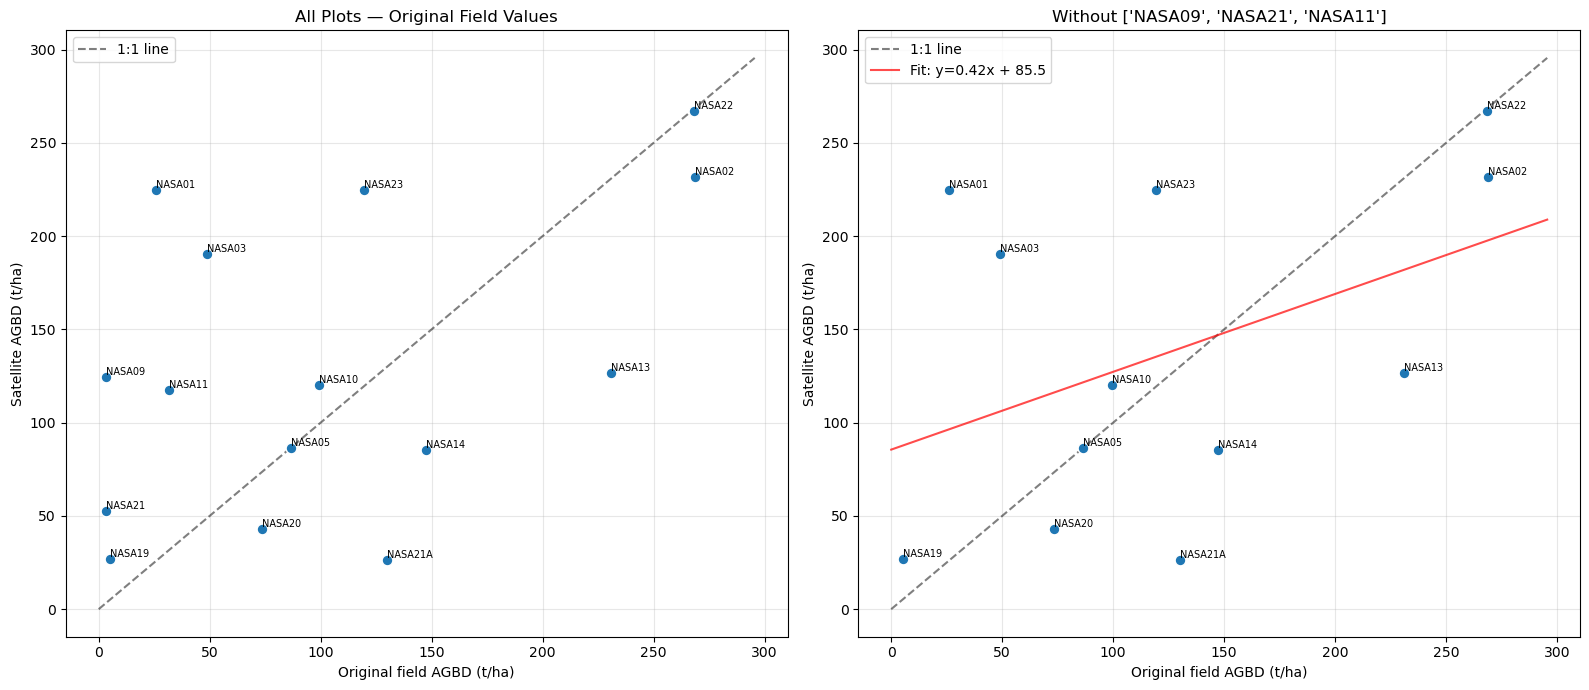


Scatter plot saved to: ../../../biomass-hackathon-2026/topics/06A-CARBON/field_vs_satellite_scatter_original.png
Comparison table saved to: ../../../biomass-hackathon-2026/topics/06A-CARBON/field_vs_satellite_comparison_original.csv

Analysis complete — original field measurements used.


In [36]:

"""
Investigate field vs satellite AGBD mismatch using ORIGINAL tree values.

Original fields used:
    m_agb   : original tree biomass (assumed kg/tree)
    d_stem  : original stem diameter (assumed metres)
    h_t_mod : original/modelled tree height (metres)

Updated values (h_t_updated, dbh_updated, agb_updated) are not
used to calculate field biomass.

IMPORTANT:
The satellite CSV uses numeric plot_id values (0–14), whereas
the field plots use names such as NASA01. This script matches
satellite rows to plots by row position, assuming both datasets
have the same order. Verify this assumption before interpreting
the comparison.
"""

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ── 0. Load data ──────────────────────────────────────────────────

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"

trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")
plots = gpd.read_file(f"{base}/Mondah_Plot_1ha.gpkg")
sat = pd.read_csv(f"{base}/plot_agbd_results.csv")

print("Tree CRS:", trees.crs)
print("Plot CRS:", plots.crs)
print("Tree count:", len(trees))
print("Plot count:", len(plots))
print("Satellite rows:", len(sat))

# Check required columns
required_tree_cols = ["plot", "m_agb", "d_stem", "h_t_mod"]
missing = [c for c in required_tree_cols if c not in trees.columns]

if missing:
    raise ValueError(f"Missing required tree columns: {missing}")

if "weighted_mean" not in sat.columns:
    raise ValueError("Satellite CSV is missing 'weighted_mean'.")

if "plot_id" not in sat.columns:
    raise ValueError("Satellite CSV is missing 'plot_id'.")

# Determine plot identifier
plot_id_col = next(
    (c for c in ["plot", "name"] if c in plots.columns),
    None
)

if plot_id_col is None:
    raise ValueError(
        "Could not find a 'plot' or 'name' column in the plot GeoPackage."
    )

# Calculate plot areas in hectares
if plots.crs is None:
    raise ValueError("Plot CRS is missing; cannot calculate plot areas.")

if plots.crs.is_projected:
    plots["area_ha"] = plots.geometry.area / 10000
else:
    plots_projected = plots.to_crs(plots.estimate_utm_crs())
    plots["area_ha"] = plots_projected.geometry.area / 10000

# Clean original measurement columns
trees = trees.copy()

for col in ["m_agb", "d_stem", "h_t_mod"]:
    trees[col] = pd.to_numeric(trees[col], errors="coerce")
    trees.loc[trees[col] <= -9990, col] = np.nan

# ── 0.1. Check satellite-to-plot mapping ──────────────────────────

print("\n" + "=" * 90)
print("SATELLITE-TO-PLOT MAPPING CHECK")
print("=" * 90)

print("Plot order:")
print(plots[plot_id_col].astype(str).tolist())

print("\nSatellite plot_id values:")
print(sat["plot_id"].tolist())

if len(plots) != len(sat):
    raise ValueError(
        f"Cannot safely match by row position: {len(plots)} plots "
        f"but {len(sat)} satellite rows."
    )

expected_ids = list(range(len(plots)))
actual_ids = pd.to_numeric(sat["plot_id"], errors="coerce").tolist()

if actual_ids != expected_ids:
    print(
        "WARNING: satellite plot_id values are not exactly 0, 1, 2, ... "
        "in row order. Verify the mapping before interpreting results."
    )
else:
    print(
        "Satellite IDs are sequential. Row-position matching will be used, "
        "but sequential IDs alone do not prove that the plot order matches."
    )

# ── Helper functions ──────────────────────────────────────────────

def get_satellite_value(position):
    """Get satellite weighted_mean by row position."""
    value = pd.to_numeric(
        sat.iloc[position]["weighted_mean"],
        errors="coerce"
    )
    return float(value) if pd.notna(value) else np.nan


def get_plot_trees(plot_name):
    """Select trees assigned to a named plot."""
    return trees[trees["plot"].astype(str) == str(plot_name)].copy()


def get_valid_biomass(pt):
    """Keep positive original m_agb values only."""
    return pt.loc[
        pt["m_agb"].notna() & (pt["m_agb"] > 0)
    ].copy()


def print_stats(label, df):
    """Print field-versus-satellite comparison statistics."""
    df = df.dropna(subset=["field", "satellite"])

    print(f"\n  {label} (n={len(df)}):")

    if df.empty:
        print("    No valid plots to compare.")
        return

    field = df["field"].to_numpy(dtype=float)
    satellite = df["satellite"].to_numpy(dtype=float)
    diff = satellite - field

    ss_res = np.sum((satellite - field) ** 2)
    ss_tot = np.sum((field - field.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    print(f"    Bias (satellite - field): {diff.mean():.2f} t/ha")
    print(f"    MAE:                      {np.mean(np.abs(diff)):.2f} t/ha")
    print(f"    RMSE:                     {np.sqrt(np.mean(diff**2)):.2f} t/ha")
    print(f"    R²:                       {r2:.4f}")
    print(f"    Mean field:               {field.mean():.2f} t/ha")
    print(f"    Mean satellite:           {satellite.mean():.2f} t/ha")
    print(f"    Median field:             {np.median(field):.2f} t/ha")
    print(f"    Median satellite:         {np.median(satellite):.2f} t/ha")


# ── 1. Per-plot investigation — original values only ───────────────

print("\n" + "=" * 90)
print("DETAILED PLOT INVESTIGATION — ORIGINAL VALUES")
print("=" * 90)

comparison_rows = []

for pos, (_, row) in enumerate(plots.iterrows()):
    plot_name = str(row[plot_id_col])
    area_ha = row["area_ha"]

    pt = get_plot_trees(plot_name)
    valid_biomass = get_valid_biomass(pt)

    # Original field biomass, kg converted to tonnes per hectare
    total_agb_kg = valid_biomass["m_agb"].sum()

    field_agbd = (
        total_agb_kg / 1000 / area_ha
        if pd.notna(area_ha) and area_ha > 0
        else np.nan
    )

    satellite_agbd = get_satellite_value(pos)

    difference = (
        satellite_agbd - field_agbd
        if pd.notna(satellite_agbd) and pd.notna(field_agbd)
        else np.nan
    )

    flag = (
        "OUTLIER"
        if pd.notna(difference) and abs(difference) > 80
        else "OK"
        if pd.notna(difference)
        else "NO SATELLITE VALUE"
    )

    print(f"\n{'-' * 70}")
    print(f"Plot: {plot_name} [{flag}]")
    print(f"{'-' * 70}")
    print(f"  Area:                {area_ha:.3f} ha")
    print(f"  Original field AGBD: {field_agbd:.2f} t/ha")
    print(
        f"  Satellite AGBD:      {satellite_agbd:.2f} t/ha"
        if pd.notna(satellite_agbd)
        else "  Satellite AGBD:      NaN"
    )
    print(
        f"  Difference:          {difference:.2f} t/ha"
        if pd.notna(difference)
        else "  Difference:          NaN"
    )

    # Tree counts and species
    print(f"\n  Tree records: {len(pt)}")
    print(f"  Trees with positive original m_agb: {len(valid_biomass)}")

    if "species" in pt.columns:
        print(f"  Species: {pt['species'].nunique()} unique")

    # Original diameter distribution
    valid_d = pt.loc[pt["d_stem"].notna() & (pt["d_stem"] > 0)]

    if not valid_d.empty:
        diameter_cm = valid_d["d_stem"] * 100

        print("\n  Original stem diameter (d_stem):")
        print(f"    Mean:   {diameter_cm.mean():.2f} cm")
        print(f"    Median: {diameter_cm.median():.2f} cm")
        print(f"    Max:    {diameter_cm.max():.2f} cm")
        print(
            f"    <10 cm: {(diameter_cm < 10).sum()} trees "
            f"({(diameter_cm < 10).mean() * 100:.1f}%)"
        )
        print(
            f"    10–30 cm: "
            f"{((diameter_cm >= 10) & (diameter_cm < 30)).sum()} trees"
        )
        print(
            f"    >=30 cm: {(diameter_cm >= 30).sum()} trees "
            f"({(diameter_cm >= 30).mean() * 100:.1f}%)"
        )

    # Original/modelled height distribution
    valid_h = pt.loc[pt["h_t_mod"].notna() & (pt["h_t_mod"] > 0)]

    if not valid_h.empty:
        print("\n  Original/modelled height (h_t_mod):")
        print(f"    Mean:   {valid_h['h_t_mod'].mean():.2f} m")
        print(f"    Median: {valid_h['h_t_mod'].median():.2f} m")
        print(f"    Max:    {valid_h['h_t_mod'].max():.2f} m")

    # Top 5 original biomass contributors
    top5 = valid_biomass.nlargest(5, "m_agb")

    if not top5.empty:
        top5_pct = (
            top5["m_agb"].sum() / total_agb_kg * 100
            if total_agb_kg > 0
            else np.nan
        )

        print(f"\n  Top 5 trees account for {top5_pct:.1f}% of field biomass:")

        for _, tree in top5.iterrows():
            species = (
                str(tree["species"])
                if "species" in pt.columns and pd.notna(tree.get("species"))
                else "Unknown"
            )

            diameter_cm = (
                tree["d_stem"] * 100
                if pd.notna(tree["d_stem"])
                else np.nan
            )
            height_m = (
                tree["h_t_mod"]
                if pd.notna(tree["h_t_mod"])
                else np.nan
            )

            print(
                f"    {species:30s} "
                f"Stem={diameter_cm:.1f} cm  "
                f"H={height_m:.1f} m  "
                f"AGB={tree['m_agb']:.1f} kg"
            )

    # Tree status, if available
    if "status" in pt.columns:
        print("\n  Tree status:")
        print(pt["status"].value_counts(dropna=False).to_string())

    comparison_rows.append({
        "plot": plot_name,
        "area_ha": area_ha,
        "n_trees": len(pt),
        "n_valid_biomass": len(valid_biomass),
        "field_agb_kg": total_agb_kg,
        "field": field_agbd,
        "satellite": satellite_agbd,
        "diff": difference,
    })


# ── 2. Spatial check — plot centroids and distances ────────────────

print("\n\n" + "=" * 90)
print("SPATIAL CHECK — PLOT CENTROIDS AND DISTANCES")
print("=" * 90)

# Calculate centroids in projected coordinates
if plots.crs.is_projected:
    centroids = plots.geometry.centroid
else:
    projected = plots.to_crs(plots.estimate_utm_crs())
    centroids = projected.geometry.centroid

for i in range(len(plots)):
    plot_name = str(plots.iloc[i][plot_id_col])
    cx, cy = centroids.iloc[i].x, centroids.iloc[i].y

    print(f"  {plot_name}: centroid=({cx:.1f}, {cy:.1f})")

    distances = [
        centroids.iloc[i].distance(centroids.iloc[j])
        for j in range(len(plots))
        if j != i
    ]

    if distances:
        print(f"    Nearest plot: {min(distances):.1f} m away")


# ── 3. Statistics with and without outliers ────────────────────────

print("\n\n" + "=" * 90)
print("STATS WITH AND WITHOUT OUTLIERS — ORIGINAL VALUES")
print("=" * 90)

comp_df = pd.DataFrame(comparison_rows)

print("\nPer-plot comparison:")
print(comp_df.round(2).to_string(index=False))

# Keep only plots with both field and satellite values
valid_comp = comp_df.dropna(subset=["field", "satellite"]).copy()

print_stats("ALL PLOTS", valid_comp)

# This is a high-biomass threshold, not a direct forest-age measurement
high_biomass = valid_comp[valid_comp["field"] >= 10]
print_stats("HIGH-BIOMASS PLOTS (field >= 10 t/ha)", high_biomass)

# Close matches
close_matches = valid_comp[
    (valid_comp["satellite"] - valid_comp["field"]).abs() < 100
]
print_stats("CLOSE MATCHES (absolute difference < 100 t/ha)", close_matches)

# Exclude selected outliers
outliers = ["NASA09", "NASA21", "NASA11"]

without_outliers = valid_comp[
    ~valid_comp["plot"].astype(str).isin(outliers)
]
print_stats(f"WITHOUT SELECTED OUTLIERS {outliers}", without_outliers)


# ── 4. Scatter plots ───────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))


def add_scatter(ax, df, title, fit_line=False):
    """Draw field-versus-satellite scatter plot."""
    ax.set_xlabel("Original field AGBD (t/ha)")
    ax.set_ylabel("Satellite AGBD (t/ha)")
    ax.set_title(title)
    ax.grid(alpha=0.3)

    if df.empty:
        ax.text(
            0.5, 0.5,
            "No valid plots",
            transform=ax.transAxes,
            ha="center",
            va="center"
        )
        return

    ax.scatter(
        df["field"],
        df["satellite"],
        s=60,
        edgecolors="white",
        zorder=3
    )

    for _, item in df.iterrows():
        ax.annotate(
            str(item["plot"]),
            (item["field"], item["satellite"]),
            fontsize=7,
            ha="left",
            va="bottom"
        )

    max_value = max(df["field"].max(), df["satellite"].max())
    limit = max_value * 1.1 if max_value > 0 else 1

    ax.plot(
        [0, limit],
        [0, limit],
        "k--",
        alpha=0.5,
        label="1:1 line"
    )

    if fit_line and len(df) >= 2 and df["field"].nunique() >= 2:
        slope, intercept = np.polyfit(
            df["field"].to_numpy(),
            df["satellite"].to_numpy(),
            1
        )

        x_fit = np.linspace(0, limit, 100)

        ax.plot(
            x_fit,
            slope * x_fit + intercept,
            "r-",
            alpha=0.7,
            label=f"Fit: y={slope:.2f}x + {intercept:.1f}"
        )

    ax.legend()


add_scatter(
    axes[0],
    valid_comp,
    "All Plots — Original Field Values"
)

add_scatter(
    axes[1],
    without_outliers,
    f"Without {outliers}",
    fit_line=True
)

plt.tight_layout()

output_path = f"{base}/field_vs_satellite_scatter_original.png"
plt.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"\nScatter plot saved to: {output_path}")


# ── 5. Export comparison table ──────────────────────────────────────

csv_output = f"{base}/field_vs_satellite_comparison_original.csv"
comp_df.to_csv(csv_output, index=False)

print(f"Comparison table saved to: {csv_output}")
print("\nAnalysis complete — original field measurements used.")



Loaded 202 subplots, 28 plots
✓ Saved 202 subplots to gabon_subplots.gpkg
✓ Saved 28 plots to gabon_plots.gpkg

Plot summary:
Plot_ID  n_subplots  field_agbd_tha  plot_area_ha  year_census
 LNL-01           4           0.000           1.0         2016
 LNL-02           4           1.175           1.0         2016
 LNL-03           4          27.475           1.0         2016
 LNL-04           2         220.000           0.5         2016
 LNL-05           2          60.750           0.5         2016
 LNL-06           2         176.150           0.5         2016
 LNL-07           4         331.250           1.0         2016
 LNL-08           4         288.000           1.0         2016
 LNL-09           4         357.525           1.0         2016
 LNL-10           4         403.325           1.0         2016
 LNL-11           4         391.450           1.0         2016
 LNL-12           4         364.625           1.0         2016
 MON-01           4          29.375           1.0      

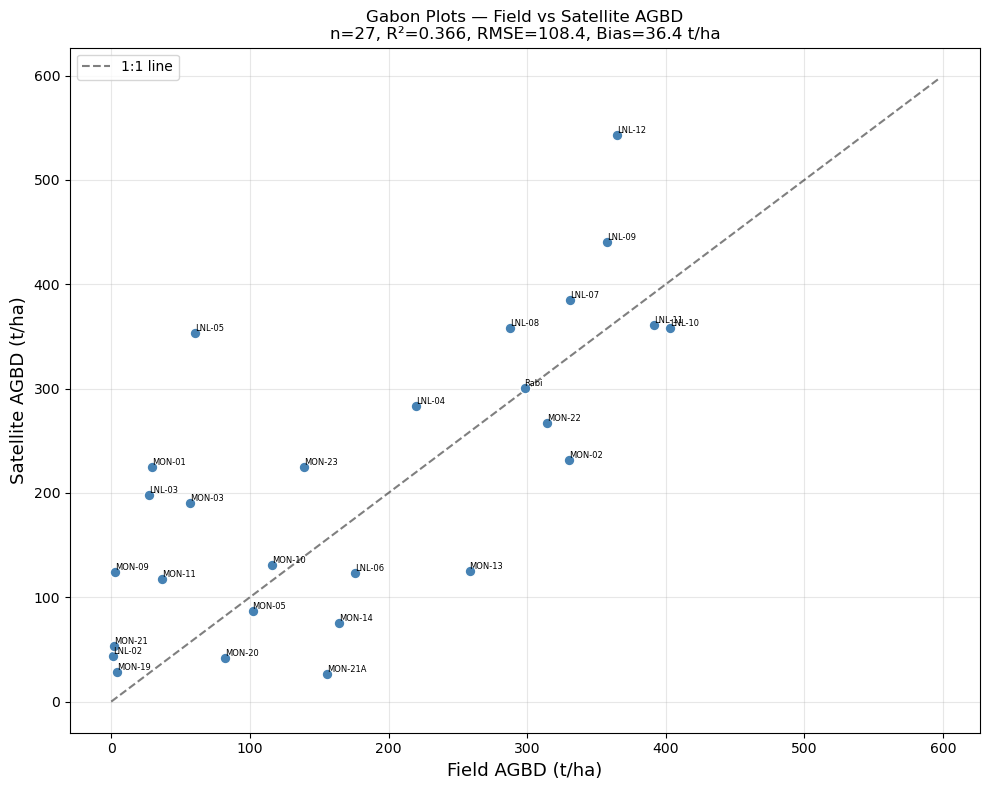


✓ Scatter plot saved
✓ Excel saved to ../../../biomass-hackathon-2026/topics/06A-CARBON/gabon_field_vs_satellite.xlsx


In [50]:
"""
1. Load Gabon plots CSV (subplots with corner coordinates)
2. Build polygon geometries from corners → GPKG
3. Aggregate subplots to plot level (field AGBD)
4. Extract satellite AGBD per plot from Congo Basin raster
5. Compare field vs satellite
6. Export Excel
"""
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.features import rasterize
from rasterio.transform import from_bounds
from shapely.geometry import Polygon

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"

# ── 1. Load CSV ──────────────────────────────────────────────────
df = pd.read_csv("plots.csv", encoding="utf-8-sig")
print(f"Loaded {len(df)} subplots, {df['Plot_ID'].nunique()} plots")

# ── 2. Build subplot polygons from corner coordinates ────────────
# Corners: NW → NE → SE → SW → close
polygons = []
for _, row in df.iterrows():
    try:
        poly = Polygon([
            (row["Lon_NW"], row["Lat_NW"]),
            (row["Lon_NE"], row["Lat_NE"]),
            (row["Lon_SE"], row["Lat_SE"]),
            (row["Lon_SW"], row["Lat_SW"]),
            (row["Lon_NW"], row["Lat_NW"]),  # close
        ])
        polygons.append(poly)
    except:
        polygons.append(None)

df["geometry"] = polygons
gdf = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:4326")
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]

# Save all subplots
gdf.to_file(f"{base}/gabon_subplots.gpkg", driver="GPKG")
print(f"✓ Saved {len(gdf)} subplots to gabon_subplots.gpkg")

# ── 3. Aggregate to plot level ───────────────────────────────────
# Each subplot is 0.25 ha, AGB_Chave is in t/ha
# For plot-level: weighted average of subplots (they're all same size)
plot_agg = gdf.groupby("Plot_ID").agg(
    n_subplots=("SubPlot_Id", "count"),
    field_agbd_tha=("AGB_Chave", "mean"),  # mean of subplots = plot-level t/ha
    field_agbd_std=("AGB_Chave", "std"),
    lat=("Lat_Cnt", "first"),
    lon=("Lon_Cnt", "first"),
    year_census=("YearCensus", "first"),
    network=("Network", "first"),
    plot_area_ha=("PlotArea", lambda x: x.sum()),  # total area
    forest_status=("ForestStatus", "first"),
    h_lorey_chave=("HLoreyChave", "mean"),
    h_max_chave=("HMaxChave", "max"),
).reset_index()

# Build plot-level polygons (dissolve subplots)
plot_geoms = gdf.dissolve(by="Plot_ID").geometry.reset_index()
plot_agg = plot_agg.merge(plot_geoms, on="Plot_ID")
plot_gdf = gpd.GeoDataFrame(plot_agg, geometry="geometry", crs="EPSG:4326")

plot_gdf.to_file(f"{base}/gabon_plots.gpkg", driver="GPKG")
print(f"✓ Saved {len(plot_gdf)} plots to gabon_plots.gpkg")
print(f"\nPlot summary:")
print(plot_gdf[["Plot_ID", "n_subplots", "field_agbd_tha", "plot_area_ha", "year_census"]].to_string(index=False))

# ── 4. Extract satellite AGBD per plot ───────────────────────────
sat_path = "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif"
OVERSAMPLE = 10

def fractional_weights(geom, shape, tf):
    h, w = shape
    fh, fw = h * OVERSAMPLE, w * OVERSAMPLE
    bounds = rasterio.transform.array_bounds(h, w, tf)
    ftf = from_bounds(*bounds, fw, fh)
    fm = rasterize([geom.__geo_interface__], out_shape=(fh, fw),
                   transform=ftf, fill=0, default_value=1, dtype=np.uint8)
    return fm.reshape(h, OVERSAMPLE, w, OVERSAMPLE).mean(axis=(1, 3))

results = []

with rasterio.open(sat_path) as src:
    print(f"\nRaster: {src.crs}, res={src.res}")
    plot_src = plot_gdf.to_crs(src.crs) if plot_gdf.crs != src.crs else plot_gdf

    for idx, row in plot_src.iterrows():
        pn = plot_gdf.iloc[idx]["Plot_ID"]
        geom = row.geometry

        if geom is None or geom.is_empty:
            results.append({"plot": pn, "sat_agbd": np.nan, "n_pixels": 0})
            continue

        try:
            clipped, ctf = rio_mask(src, [geom.__geo_interface__],
                                    crop=True, all_touched=True,
                                    nodata=src.nodata, filled=True)
            data = clipped[0]
            weights = fractional_weights(geom, data.shape, ctf)

            valid = np.isfinite(data) & (weights > 0)
            if src.nodata is not None:
                valid &= data != src.nodata

            if valid.any():
                sat_agbd = float(np.average(data[valid], weights=weights[valid]))
                n_px = int(valid.sum())
            else:
                sat_agbd = np.nan
                n_px = 0
        except:
            sat_agbd = np.nan
            n_px = 0

        results.append({"plot": pn, "sat_agbd": sat_agbd, "n_pixels": n_px})
        print(f"  {pn}: sat={sat_agbd:.1f} t/ha ({n_px} px)" if not np.isnan(sat_agbd) else f"  {pn}: no data")

sat_df = pd.DataFrame(results)

# ── 5. Merge and compare ────────────────────────────────────────
comp = plot_gdf[["Plot_ID", "n_subplots", "field_agbd_tha", "field_agbd_std",
                 "plot_area_ha", "year_census", "network", "forest_status",
                 "h_lorey_chave", "h_max_chave"]].copy()
comp = comp.merge(sat_df, left_on="Plot_ID", right_on="plot", how="left")

comp["diff"] = comp["sat_agbd"] - comp["field_agbd_tha"]
comp["pct_diff"] = np.where(
    comp["field_agbd_tha"] > 0,
    comp["diff"] / comp["field_agbd_tha"] * 100,
    np.nan
)

print(f"\n{'='*100}")
print("GABON PLOTS — FIELD vs SATELLITE AGBD (t/ha)")
print(f"{'='*100}")
print(comp[["Plot_ID", "n_subplots", "plot_area_ha", "year_census",
            "field_agbd_tha", "sat_agbd", "n_pixels", "diff", "pct_diff"]].to_string(index=False))

# ── 6. Stats ─────────────────────────────────────────────────────
has_both = comp["sat_agbd"].notna() & (comp["field_agbd_tha"] > 0)
if has_both.any():
    f_vals = comp.loc[has_both, "field_agbd_tha"].values
    s_vals = comp.loc[has_both, "sat_agbd"].values
    diff = s_vals - f_vals
    bias = diff.mean()
    rmse = np.sqrt((diff**2).mean())
    ss_res = np.sum((s_vals - f_vals)**2)
    ss_tot = np.sum((f_vals - f_vals.mean())**2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    print(f"\n  All plots with data (n={has_both.sum()}):")
    print(f"    Bias:  {bias:.1f} t/ha")
    print(f"    RMSE:  {rmse:.1f} t/ha")
    print(f"    R²:    {r2:.4f}")

    # Filter: only plots with field > 10 t/ha
    mature = has_both & (comp["field_agbd_tha"] >= 10)
    if mature.any():
        f2 = comp.loc[mature, "field_agbd_tha"].values
        s2 = comp.loc[mature, "sat_agbd"].values
        d2 = s2 - f2
        r2_m = 1 - np.sum((s2 - f2)**2) / np.sum((f2 - f2.mean())**2)
        print(f"\n  Mature forest only, field >= 10 t/ha (n={mature.sum()}):")
        print(f"    Bias:  {d2.mean():.1f} t/ha")
        print(f"    RMSE:  {np.sqrt((d2**2).mean()):.1f} t/ha")
        print(f"    R²:    {r2_m:.4f}")

    # Filter: close matches
    close = has_both & (abs(comp["diff"]) < 100)
    if close.any():
        f3 = comp.loc[close, "field_agbd_tha"].values
        s3 = comp.loc[close, "sat_agbd"].values
        d3 = s3 - f3
        r2_c = 1 - np.sum((s3 - f3)**2) / np.sum((f3 - f3.mean())**2)
        print(f"\n  Close matches, |diff| < 100 (n={close.sum()}):")
        print(f"    Bias:  {d3.mean():.1f} t/ha")
        print(f"    RMSE:  {np.sqrt((d3**2).mean()):.1f} t/ha")
        print(f"    R²:    {r2_c:.4f}")

# ── 7. Scatter plot ──────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

valid_plots = comp[has_both]
ax.scatter(valid_plots["field_agbd_tha"], valid_plots["sat_agbd"],
           s=60, c="steelblue", edgecolors="white", zorder=3)

for _, r in valid_plots.iterrows():
    ax.annotate(r["Plot_ID"], (r["field_agbd_tha"], r["sat_agbd"]),
                fontsize=6, ha="left", va="bottom")

lim = max(valid_plots["field_agbd_tha"].max(), valid_plots["sat_agbd"].max()) * 1.1
ax.plot([0, lim], [0, lim], "k--", alpha=0.5, label="1:1 line")
ax.set_xlabel("Field AGBD (t/ha)", fontsize=13)
ax.set_ylabel("Satellite AGBD (t/ha)", fontsize=13)
ax.set_title(f"Gabon Plots — Field vs Satellite AGBD\n"
             f"n={has_both.sum()}, R²={r2:.3f}, RMSE={rmse:.1f}, Bias={bias:.1f} t/ha")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{base}/gabon_field_vs_satellite.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\n✓ Scatter plot saved")

# ── 8. Export Excel ──────────────────────────────────────────────
excel_path = f"{base}/gabon_field_vs_satellite.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    comp.drop(columns=["plot"], errors="ignore").to_excel(
        writer, sheet_name="Plot_Comparison", index=False)

    if has_both.any():
        summary = pd.DataFrame({
            "Metric": ["N plots", "Bias (t/ha)", "RMSE (t/ha)", "R²",
                        "Mean field (t/ha)", "Mean satellite (t/ha)"],
            "Value": [has_both.sum(), round(bias, 1), round(rmse, 1),
                      round(r2, 4), round(f_vals.mean(), 1), round(s_vals.mean(), 1)]
        })
        summary.to_excel(writer, sheet_name="Summary_Stats", index=False)

print(f"✓ Excel saved to {excel_path}")

Loaded 202 subplots, 28 plots
✓ Saved 202 subplots to gabon_subplots.gpkg
✓ Saved 28 plots to gabon_plots.gpkg

Plot summary:
Plot_ID  n_subplots  agb_chave  agb_local  plot_area_ha  year_census
 LNL-01           4      0.000      0.150           1.0         2016
 LNL-02           4      1.175      0.350           1.0         2016
 LNL-03           4     27.475     15.500           1.0         2016
 LNL-04           2    220.000    219.250           0.5         2016
 LNL-05           2     60.750     51.150           0.5         2016
 LNL-06           2    176.150    181.450           0.5         2016
 LNL-07           4    331.250    317.875           1.0         2016
 LNL-08           4    288.000    290.400           1.0         2016
 LNL-09           4    357.525    348.575           1.0         2016
 LNL-10           4    403.325    375.050           1.0         2016
 LNL-11           4    391.450    349.725           1.0         2016
 LNL-12           4    364.625    321.400     

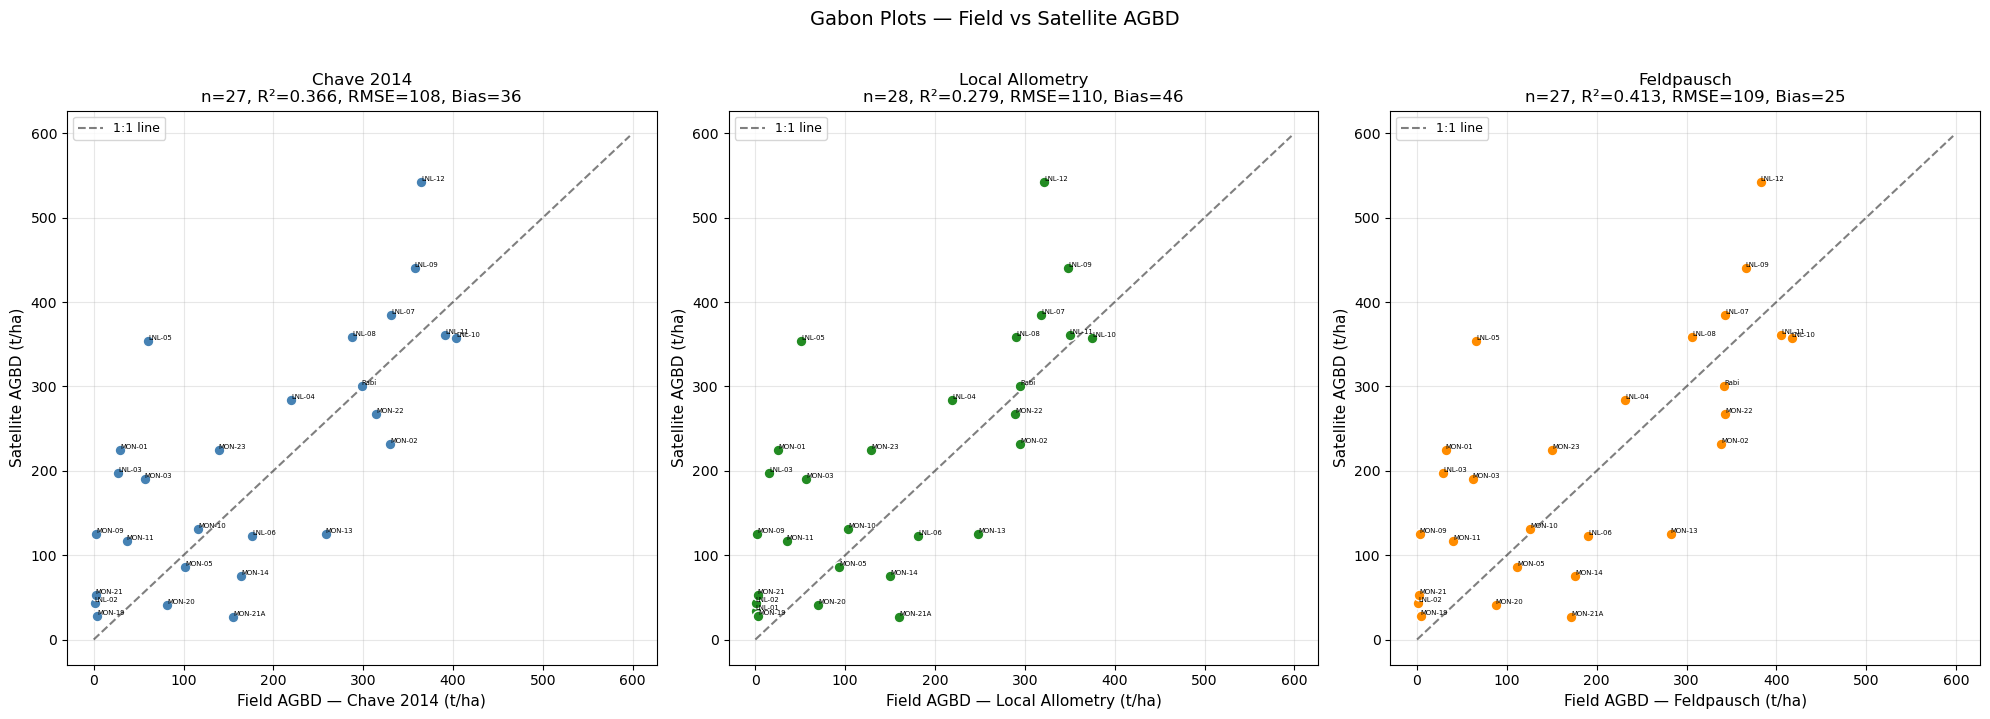


✓ Scatter plot saved
✓ Excel saved to ../../../biomass-hackathon-2026/topics/06A-CARBON/gabon_field_vs_satellite.xlsx


In [57]:
"""
1. Load Gabon plots CSV (subplots with corner coordinates)
2. Build polygon geometries from corners → GPKG
3. Aggregate subplots to plot level (field AGBD)
4. Extract satellite AGBD per plot from Congo Basin raster
5. Compare field vs satellite
6. Export Excel
"""
import pandas as pd
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.features import rasterize
from rasterio.transform import from_bounds
from shapely.geometry import Polygon

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"

# ── 1. Load CSV ──────────────────────────────────────────────────
df = pd.read_csv("plots.csv", encoding="utf-8-sig")
print(f"Loaded {len(df)} subplots, {df['Plot_ID'].nunique()} plots")

# ── 2. Build subplot polygons from corner coordinates ────────────
# Corners: NW → NE → SE → SW → close
polygons = []
for _, row in df.iterrows():
    try:
        poly = Polygon([
            (row["Lon_NW"], row["Lat_NW"]),
            (row["Lon_NE"], row["Lat_NE"]),
            (row["Lon_SE"], row["Lat_SE"]),
            (row["Lon_SW"], row["Lat_SW"]),
            (row["Lon_NW"], row["Lat_NW"]),  # close
        ])
        polygons.append(poly)
    except:
        polygons.append(None)

df["geometry"] = polygons
gdf = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:4326")
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]

# Save all subplots
gdf.to_file(f"{base}/gabon_subplots.gpkg", driver="GPKG")
print(f"✓ Saved {len(gdf)} subplots to gabon_subplots.gpkg")

# ── 3. Aggregate to plot level ───────────────────────────────────
# Each subplot is 0.25 ha, AGB_Chave is in t/ha
# For plot-level: weighted average of subplots (they're all same size)
plot_agg = gdf.groupby("Plot_ID").agg(
    n_subplots=("SubPlot_Id", "count"),
    agb_chave=("AGB_Chave", "mean"),
    agb_chave_std=("AGB_Chave", "std"),
    agb_local=("AGBLocal", "mean"),
    agb_local_std=("AGBLocal", "std"),
    agb_feldpausch=("AGBFeldpausch", "mean"),
    agb_feldpausch_std=("AGBFeldpausch", "std"),
    lat=("Lat_Cnt", "first"),
    lon=("Lon_Cnt", "first"),
    year_census=("YearCensus", "first"),
    network=("Network", "first"),
    plot_area_ha=("PlotArea", lambda x: x.sum()),
    forest_status=("ForestStatus", "first"),
    h_lorey_chave=("HLoreyChave", "mean"),
    h_lorey_local=("HLoreyLocal", "mean"),
    h_max_chave=("HMaxChave", "max"),
    h_max_local=("HMaxLocal", "max"),
    wood_density=("WoodDensity", "mean"),
    basal_area=("BA", "mean"),
    stem_density=("NDens", "mean"),
).reset_index()

# Build plot-level polygons (dissolve subplots)
plot_geoms = gdf.dissolve(by="Plot_ID").geometry.reset_index()
plot_agg = plot_agg.merge(plot_geoms, on="Plot_ID")
plot_gdf = gpd.GeoDataFrame(plot_agg, geometry="geometry", crs="EPSG:4326")

plot_gdf.to_file(f"{base}/gabon_plots.gpkg", driver="GPKG")
print(f"✓ Saved {len(plot_gdf)} plots to gabon_plots.gpkg")
print(f"\nPlot summary:")
print(plot_gdf[["Plot_ID", "n_subplots", "agb_chave", "agb_local", "plot_area_ha", "year_census"]].to_string(index=False))

# ── 4. Extract satellite AGBD per plot ───────────────────────────
sat_path = "../../../Examples_and_Data/Workshops/BIOMASS-Coding2026/Biomass_AGBD_Congo_Basin/agbd_map_L2Afullextent_congo_basin.tif"
OVERSAMPLE = 10

def fractional_weights(geom, shape, tf):
    h, w = shape
    fh, fw = h * OVERSAMPLE, w * OVERSAMPLE
    bounds = rasterio.transform.array_bounds(h, w, tf)
    ftf = from_bounds(*bounds, fw, fh)
    fm = rasterize([geom.__geo_interface__], out_shape=(fh, fw),
                   transform=ftf, fill=0, default_value=1, dtype=np.uint8)
    return fm.reshape(h, OVERSAMPLE, w, OVERSAMPLE).mean(axis=(1, 3))

results = []

with rasterio.open(sat_path) as src:
    print(f"\nRaster: {src.crs}, res={src.res}")
    plot_src = plot_gdf.to_crs(src.crs) if plot_gdf.crs != src.crs else plot_gdf

    for idx, row in plot_src.iterrows():
        pn = plot_gdf.iloc[idx]["Plot_ID"]
        geom = row.geometry

        if geom is None or geom.is_empty:
            results.append({"plot": pn, "sat_agbd": np.nan, "n_pixels": 0})
            continue

        try:
            clipped, ctf = rio_mask(src, [geom.__geo_interface__],
                                    crop=True, all_touched=True,
                                    nodata=src.nodata, filled=True)
            data = clipped[0]
            weights = fractional_weights(geom, data.shape, ctf)

            valid = np.isfinite(data) & (weights > 0)
            if src.nodata is not None:
                valid &= data != src.nodata

            if valid.any():
                sat_agbd = float(np.average(data[valid], weights=weights[valid]))
                n_px = int(valid.sum())
            else:
                sat_agbd = np.nan
                n_px = 0
        except:
            sat_agbd = np.nan
            n_px = 0

        results.append({"plot": pn, "sat_agbd": sat_agbd, "n_pixels": n_px})
        print(f"  {pn}: sat={sat_agbd:.1f} t/ha ({n_px} px)" if not np.isnan(sat_agbd) else f"  {pn}: no data")

sat_df = pd.DataFrame(results)

# ── 5. Merge and compare ────────────────────────────────────────
comp = plot_gdf[["Plot_ID", "n_subplots", "agb_chave", "agb_local", "agb_feldpausch",
                 "plot_area_ha", "year_census", "network", "forest_status",
                 "h_lorey_chave", "h_lorey_local", "h_max_chave", "h_max_local",
                 "wood_density", "basal_area", "stem_density"]].copy()
comp = comp.merge(sat_df, left_on="Plot_ID", right_on="plot", how="left")

comp["diff_chave"] = comp["sat_agbd"] - comp["agb_chave"]
comp["diff_local"] = comp["sat_agbd"] - comp["agb_local"]
comp["diff_feldpausch"] = comp["sat_agbd"] - comp["agb_feldpausch"]

print(f"\n{'='*120}")
print("GABON PLOTS — FIELD vs SATELLITE AGBD (t/ha)")
print(f"{'='*120}")
print(comp[["Plot_ID", "n_subplots", "year_census",
            "agb_chave", "agb_local", "agb_feldpausch",
            "sat_agbd", "n_pixels",
            "diff_chave", "diff_local", "diff_feldpausch"]].to_string(index=False))

# ── 6. Stats ─────────────────────────────────────────────────────
def compute_stats(label, f_vals, s_vals):
    diff = s_vals - f_vals
    bias = diff.mean()
    rmse = np.sqrt((diff**2).mean())
    ss_res = np.sum((s_vals - f_vals)**2)
    ss_tot = np.sum((f_vals - f_vals.mean())**2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
    print(f"\n  {label} (n={len(f_vals)}):")
    print(f"    Bias:  {bias:.1f} t/ha")
    print(f"    RMSE:  {rmse:.1f} t/ha")
    print(f"    R²:    {r2:.4f}")
    return {"label": label, "n": len(f_vals), "bias": round(bias, 1),
            "rmse": round(rmse, 1), "r2": round(r2, 4)}

print(f"\n{'='*80}")
print("VALIDATION STATISTICS")
print(f"{'='*80}")

all_stats = []

for agb_col, name in [("agb_chave", "Chave"), ("agb_local", "Local"), ("agb_feldpausch", "Feldpausch")]:
    has_both = comp["sat_agbd"].notna() & comp[agb_col].notna() & (comp[agb_col] > 0)
    if has_both.any():
        f_vals = comp.loc[has_both, agb_col].values
        s_vals = comp.loc[has_both, "sat_agbd"].values
        st = compute_stats(f"Satellite vs {name} (all)", f_vals, s_vals)
        all_stats.append(st)

        # Mature only
        mature = has_both & (comp[agb_col] >= 10)
        if mature.sum() >= 3:
            st2 = compute_stats(f"Satellite vs {name} (field≥10)", 
                                comp.loc[mature, agb_col].values,
                                comp.loc[mature, "sat_agbd"].values)
            all_stats.append(st2)

# Store for Excel and plot
has_both = comp["sat_agbd"].notna() & comp["agb_chave"].notna() & (comp["agb_chave"] > 0)
f_vals = comp.loc[has_both, "agb_chave"].values
s_vals = comp.loc[has_both, "sat_agbd"].values
diff = s_vals - f_vals
bias = diff.mean()
rmse = np.sqrt((diff**2).mean())
ss_res = np.sum((s_vals - f_vals)**2)
ss_tot = np.sum((f_vals - f_vals.mean())**2)
r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

# ── 7. Scatter plot ──────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
colors = {"agb_chave": "steelblue", "agb_local": "forestgreen", "agb_feldpausch": "darkorange"}
titles = {"agb_chave": "Chave 2014", "agb_local": "Local Allometry", "agb_feldpausch": "Feldpausch"}

for i, (agb_col, ax) in enumerate(zip(["agb_chave", "agb_local", "agb_feldpausch"], axes)):
    valid = comp["sat_agbd"].notna() & comp[agb_col].notna() & (comp[agb_col] > 0)
    vp = comp[valid]
    
    ax.scatter(vp[agb_col], vp["sat_agbd"], s=60, c=colors[agb_col],
               edgecolors="white", zorder=3)
    
    for _, r in vp.iterrows():
        ax.annotate(r["Plot_ID"], (r[agb_col], r["sat_agbd"]),
                    fontsize=5, ha="left", va="bottom")
    
    lim = max(vp[agb_col].max(), vp["sat_agbd"].max()) * 1.1 if len(vp) else 500
    ax.plot([0, lim], [0, lim], "k--", alpha=0.5, label="1:1 line")
    
    # Stats
    f_v = vp[agb_col].values
    s_v = vp["sat_agbd"].values
    d = s_v - f_v
    ss_r = np.sum((s_v - f_v)**2)
    ss_t = np.sum((f_v - f_v.mean())**2)
    r2_i = 1 - ss_r / ss_t if ss_t > 0 else np.nan
    
    ax.set_xlabel(f"Field AGBD — {titles[agb_col]} (t/ha)", fontsize=11)
    ax.set_ylabel("Satellite AGBD (t/ha)", fontsize=11)
    ax.set_title(f"{titles[agb_col]}\nn={valid.sum()}, R²={r2_i:.3f}, RMSE={np.sqrt((d**2).mean()):.0f}, Bias={d.mean():.0f}")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle("Gabon Plots — Field vs Satellite AGBD", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f"{base}/gabon_field_vs_satellite.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\n✓ Scatter plot saved")

# ── 8. Export Excel ──────────────────────────────────────────────
excel_path = f"{base}/gabon_field_vs_satellite.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    comp.drop(columns=["plot"], errors="ignore").to_excel(
        writer, sheet_name="Plot_Comparison", index=False)

    if all_stats:
        summary = pd.DataFrame(all_stats)
        summary.to_excel(writer, sheet_name="Summary_Stats", index=False)

print(f"✓ Excel saved to {excel_path}")

In [62]:
import pandas as pd

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"

# Use the results from validate_gabon_plots.py (correct extraction)
df = pd.read_excel(f"{base}/gabon_field_vs_satellite.xlsx", sheet_name="Plot_Comparison")

# Sort by area if available, otherwise just show
cols = ["Plot_ID", "n_subplots", "plot_area_ha", "agb_chave", "agb_local", "sat_agbd", "diff_chave"]
cols = [c for c in cols if c in df.columns]

df_sorted = df.sort_values("plot_area_ha" if "plot_area_ha" in df.columns else "n_subplots", ascending=False)

print(f"{'Plot':>8} {'Area(ha)':>9} {'Sub':>4} {'Chave':>7} {'Local':>7} {'Satellite':>10} {'Diff':>8} {'Diff%':>8}")
print("-" * 70)
for _, r in df_sorted.iterrows():
    area = r.get("plot_area_ha", r.get("n_subplots", 0) * 0.25)
    sat = f"{r['sat_agbd']:.1f}" if pd.notna(r.get("sat_agbd")) else "N/A"
    diff = f"{r.get('diff_chave', np.nan):.1f}" if pd.notna(r.get("diff_chave")) else "N/A"
    pct = f"{r.get('diff_chave', 0) / r['agb_chave'] * 100:.0f}%" if r["agb_chave"] > 0 and pd.notna(r.get("diff_chave")) else "N/A"
    print(f"{r['Plot_ID']:>8} {area:>9.2f} {r['n_subplots']:>4} {r['agb_chave']:>7.1f} {r.get('agb_local', 0):>7.1f} {sat:>10} {diff:>8} {pct:>8}")

    Plot  Area(ha)  Sub   Chave   Local  Satellite     Diff    Diff%
----------------------------------------------------------------------
    Rabi     25.00  100   298.2   295.1      300.9      2.8       1%
  LNL-02      1.00    4     1.2     0.3       43.3     42.1    3583%
  MON-23      1.00    4   139.2   128.8      224.6     85.3      61%
  MON-22      1.00    4   314.6   289.1      267.1    -47.5     -15%
 MON-21A      1.00    4   155.4   160.3       26.3   -129.1     -83%
  MON-21      1.00    4     2.3     2.4       52.8     50.5    2222%
  MON-20      1.00    4    81.9    70.2       41.4    -40.4     -49%
  MON-19      1.00    4     3.9     3.5       28.4     24.6     634%
  MON-14      1.00    4   164.1   149.9       75.4    -88.7     -54%
  MON-13      1.00    4   258.4   247.8      125.0   -133.5     -52%
  MON-11      1.00    4    36.6    35.0      117.4     80.7     220%
  MON-10      1.00    4   116.2   103.4      130.8     14.6      13%
  MON-09      1.00    4     2.7 

In [8]:
 import geopandas as gpd
import numpy as np
import pandas as pd

base = "../../../biomass-hackathon-2026/topics/06A-CARBON"
trees = gpd.read_file(f"{base}/Mondah_Trees_updated.gpkg")
plots = gpd.read_file(f"{base}/Mondah_Plot_1ha.gpkg")
sat = pd.read_csv(f"{base}/plot_agbd_results.csv")

if plots.crs.is_projected:
    plots["area_ha"] = plots.geometry.area / 10000

results = []
for idx, row in plots.iterrows():
    pn = row.get("name", row.get("plot", idx))
    ah = row["area_ha"]
    pt = trees[trees["plot"] == pn]

    # 2016 field
    field_2016 = pt.loc[pt["m_agb"] > 0, "m_agb"].sum() / 1000 / ah
    # 2026 updated
    field_2026 = pt.loc[pt["agb_updated"] > 0, "agb_updated"].sum() / 1000 / ah
    # Satellite
    sat_val = float(sat.iloc[idx]["weighted_mean"]) if idx < len(sat) and pd.notna(sat.iloc[idx]["weighted_mean"]) else np.nan

    results.append({
        "plot": pn, "area_ha": round(ah, 2),
        "field_2016": round(field_2016, 1),
        "field_2026_updated": round(field_2026, 1),
        "satellite": round(sat_val, 1) if not np.isnan(sat_val) else np.nan,
        "diff_sat_vs_2016": round(sat_val - field_2016, 1) if not np.isnan(sat_val) else np.nan,
        "diff_sat_vs_2026": round(sat_val - field_2026, 1) if not np.isnan(sat_val) else np.nan,
    })

df = pd.DataFrame(results)
print(df.to_string(index=False))

# Stats for both
for col, label in [("field_2016", "2016"), ("field_2026_updated", "2026 updated")]:
    has = df["satellite"].notna() & (df[col] > 0)
    if has.any():
        f = df.loc[has, col].values
        s = df.loc[has, "satellite"].values
        d = s - f
        r2 = 1 - np.sum((s-f)**2) / np.sum((f-f.mean())**2)
        print(f"\n  Satellite vs {label} (n={has.sum()}):")
        print(f"    Bias: {d.mean():.1f}  RMSE: {np.sqrt((d**2).mean()):.1f}  R²: {r2:.4f}")

   plot  area_ha  field_2016  field_2026_updated  satellite  diff_sat_vs_2016  diff_sat_vs_2026
 NASA01      1.0        25.9                35.0      224.7             198.8             189.7
 NASA02      1.0       268.7               325.8      231.9             -36.8             -93.9
 NASA03      1.0        48.9               139.7      190.5             141.6              50.8
 NASA05      1.0        86.5                73.4       86.6               0.0              13.2
 NASA09      1.0         3.4                 0.2      124.6             121.1             124.4
 NASA10      1.0        99.4               112.1      120.4              21.1               8.3
 NASA11      1.0        31.4                17.9      117.4              85.9              99.5
 NASA13      1.0       231.0               391.6      126.6            -104.4            -265.0
 NASA14      1.0       147.4               129.8       85.4             -62.0             -44.4
 NASA19      1.0         5.3            